[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/39Matheus/AED2/blob/Work_Branch/LOTUS.ipynb)

# L.O.T.U.S. — comparação de contextos lexicais em chinês e japonês

Aprendizes encontram caracteres iguais em palavras de línguas diferentes. **Quais caracteres
compartilhados apresentam contextos de coocorrência mais semelhantes ou diferentes nos
dicionários CC-CEDICT e JMdict? O resultado muda ao comparar o japonês com o chinês
tradicional ou simplificado?**

O público são estudantes interessados em explorar palavras associadas a esses caracteres.
A hipótese original sobre divergência semântica continua como motivação: esta análise
**mede estrutura ortográfica, não equivalência de significado nem falsos cognatos**.
As definições ficam disponíveis para inspeção qualitativa; confirmar divergência semântica
exigiria uma avaliação linguística adicional.

Execute as células na ordem: configuração → dados → limpeza/amostragem → redes → análise
→ visualizações → conclusão. Não é necessário usar todas as ferramentas do curso.

## 1. Modelagem e escolhas

- **Nós:** formas escritas de palavras, separadas por idioma/variante, e caracteres Han.
- **Aresta palavra–caractere:** a palavra contém aquele caractere. Grafo simples, não dirigido,
  sem peso; repetição do caractere na mesma palavra conta uma vez.
- **Partições:** palavras e caracteres. Palavras iguais em línguas distintas continuam sendo
  nós distintos; caracteres com o mesmo código Unicode se unem na composição das redes.
- **Projeção sobre caracteres:** dois caracteres se ligam se aparecem numa mesma palavra;
  o peso conta quantas formas escritas distintas os contêm. O Jaccard compara conjuntos de
  vizinhos dessa projeção entre línguas, no universo de caracteres compartilhados.
- **Simplificado × tradicional:** correspondência do CC-CEDICT é uma relação extra usada
  somente na visualização, em outro grafo. Ela não entra nas métricas bipartidas.
- **Fora do modelo:** frequência de uso, ordem e repetição dos caracteres, pronúncia como
  relação, equivalência semântica e equivalência entre grafias Han diferentes. NFC é aplicado;
  não há conversão automática simplificado/tradicional/japonês nem NFKC.

Conceitos: modelagem/grau (semana 2), componentes/clustering (semana 4), núcleos
(semana 5), redes bipartidas, matriz de incidência, projeção, força e Jaccard (semana 6).

## 2. Configuração: amostra ou população completa

`USE_SAMPLE = False` usa **todas as unidades elegíveis após a limpeza**: pares de grafias
chinesas e formas japonesas com Han. `USE_SAMPLE = True` ativa a amostragem com os limites
`N_CN` e `N_JP` (5.000 por padrão) e a semente `SEED`. A população é a dos dicionários
baixados, não a de todas as palavras existentes ou utilizadas nas línguas.

Localmente, instale `requirements.txt`. No Colab, a próxima célula instala as mesmas versões.
A fonte CJK é opcional para os cálculos; para rótulos legíveis em Linux, instale
`fonts-noto-cjk` e reinicie o kernel. Os limites das visualizações continuam independentes
da seleção dos dados: desenhar todos os nós tornaria os gráficos ilegíveis.

A fonte pode não cobrir algum Han raro nas figuras; os dados e cálculos preservam
os caracteres originais mesmo nesses casos.

O controle visual incorporado da versão do grupo está em `SHARED_CHAR_MODE`, com modos
`"top_frequency"`, `"random"` e `"manual"`. As listas manuais tradicional/simplificada são
independentes e foram preservadas do arquivo alternativo. Veja a seção 11.1 para fixar ou
recalcular as listas. Esses controles não selecionam linhas dos dicionários.

In [1]:
import sys
import subprocess

if "google.colab" in sys.modules:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "networkx==3.4.2", "pandas==2.2.3", "matplotlib==3.10.0",
                           "requests==2.32.3", "pyvis==0.3.2", "scipy==1.17.0"])

import gzip
import hashlib
import html as _html
import io
import json
import re
import random
import unicodedata
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import requests
import scipy
from IPython.display import HTML, display
from matplotlib.font_manager import FontProperties

USE_SAMPLE = False  # False: população completa; True: amostra com os limites abaixo.
N_CN = 5000
N_JP = 5000
SEED = 42

# Seleção dos caracteres para os desenhos; não altera as métricas da população.
# top_frequency: grau dicionarizado equilibrado entre idiomas; random: sorteio; manual: listas abaixo.
SHARED_CHAR_MODE = "manual"
SHARED_CHAR_COUNT = 18
SHARED_CHAR_SEED = 42
MANUAL_SHARED_CHARS_TRAD = ['言', '子', '見', '化', '手', '方', '人', '語', '動', '上', '式', '通', '間', '馬', '無', '行', '生', '線']
MANUAL_SHARED_CHARS_SIMP = ['言', '子', '化', '手', '方', '人', '上', '式', '通', '行', '来', '生', '切', '小', '部', '字', '如', '天']
INTERACTIVE_INLINE = True  # Exibe os três grafos interativos dentro do notebook.
DATA_DIR = Path("data/raw")
RESULTS_DIR = Path("resultados")
FIGURES_DIR = RESULTS_DIR / "figuras"
GRAPHS_DIR = RESULTS_DIR / "grafos"
for folder in (DATA_DIR, RESULTS_DIR, FIGURES_DIR, GRAPHS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

font_candidates = sorted(f for f in fm.findSystemFonts()
                         if "NotoSansCJK-Regular" in f or "NotoSerifCJK-Regular" in f)
cjk_font = FontProperties(fname=font_candidates[0]) if font_candidates else FontProperties()
if not font_candidates:
    print("Fonte CJK ausente: os cálculos funcionam, mas alguns rótulos podem não aparecer.")
plt.rcParams["figure.dpi"] = 110


def save_figure(fig, title):
    slug = unicodedata.normalize("NFKD", title).encode("ascii", "ignore").decode()
    slug = re.sub(r"[^a-z0-9]+", "_", slug.lower()).strip("_")
    fig.savefig(FIGURES_DIR / f"{slug}.png", dpi=150, bbox_inches="tight")

## 3. Obtenção dos dados reais

Fontes: [CC-CEDICT/MDBG](https://www.mdbg.net/chinese/dictionary?page=cedict), chinês–inglês,
e [JMdict/EDRDG](https://www.edrdg.org/jmdict/j_jmdict.html), japonês–inglês (`JMdict_e`).
São dicionários, não corpora de frequência. Créditos e licenças estão no README.

Os `.gz` ficam em cache em `data/raw/`. A requisição usa timeout, verificação TLS padrão e
checagem de HTTP/gzip. Para atualizar, remova os dois arquivos do cache. O manifesto registra
URL, SHA-256 e momento da primeira leitura desta cópia. Os arquivos remotos são atualizados:
mesma semente sem os mesmos arquivos não garante os mesmos resultados.

In [2]:
SOURCES = {
    "cedict_1_0_ts_utf-8_mdbg.txt.gz":
        "https://www.mdbg.net/chinese/export/cedict/cedict_1_0_ts_utf-8_mdbg.txt.gz",
    "JMdict_e.gz": "https://ftp.edrdg.org/pub/Nihongo/JMdict_e.gz",
}
manifest_path = DATA_DIR / "manifesto.json"
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}


def load_dictionary(filename):
    path = DATA_DIR / filename
    if path.exists():
        compressed = path.read_bytes()
    else:
        response = requests.get(SOURCES[filename], timeout=(15, 120))
        response.raise_for_status()
        compressed = response.content
    content = gzip.decompress(compressed)  # valida também arquivos em cache
    digest = hashlib.sha256(compressed).hexdigest()
    if not path.exists():
        path.write_bytes(compressed)
    if manifest.get(filename, {}).get("sha256") != digest:
        manifest[filename] = {
            "url": SOURCES[filename], "sha256": digest, "bytes": len(compressed),
            "primeira_leitura_utc": datetime.now(timezone.utc).isoformat(),
        }
    manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    return content


cedict_bytes = load_dictionary("cedict_1_0_ts_utf-8_mdbg.txt.gz")
jmdict_bytes = load_dictionary("JMdict_e.gz")
display(pd.DataFrame(manifest).T[["bytes", "sha256"]])

,bytes,sha256
cedict_1_0_ts_utf-8_mdbg.txt.gz,3981631,2d42d41f75df8708d9d9b236d8ae15ecf1cef525aef8eb...
JMdict_e.gz,10586544,e84b7515b481485fe17f79939144bfbbd5456386768998...


## 4. Parsing e limpeza

CC-CEDICT: ignora comentários e reporta linhas não reconhecidas. JMdict: preserva **todas as
grafias `keb`**, não só a primeira; respeita restrições de grafia de leituras e sentidos.
As definições são inglesas e são reunidas por grafia; isso não alinha sentidos entre línguas.
Formas sem Han ficam fora. Homógrafos/sentidos repetidos se unem por forma escrita para
que uma entrada com várias definições não aumente o grau artificialmente.

In [3]:
def is_han(char):
    value = ord(char)
    return any(start <= value <= end for start, end in (
        (0x3400, 0x4DBF), (0x4E00, 0x9FFF), (0xF900, 0xFAFF),
        (0x20000, 0x2A6DF), (0x2A700, 0x2B73F), (0x2B740, 0x2B81F),
        (0x2B820, 0x2CEAF), (0x2CEB0, 0x2EBEF), (0x2EBF0, 0x2EE5F),
        (0x2F800, 0x2FA1F), (0x30000, 0x3134F), (0x31350, 0x323AF), (0x323B0, 0x3347F),
    ))


def extract_han(text):
    return sorted({char for char in text if is_han(char)})


def normalize(text):
    return unicodedata.normalize("NFC", text.strip())


def join_unique(values):
    return "; ".join(dict.fromkeys(value for value in values if value))


def parse_cedict(content):
    pattern = re.compile(r"^(\S+)\s+(\S+)\s+\[(.*?)\]\s+/(.*)/$")
    entries, rejected = [], 0
    for line in content.decode("utf-8").splitlines():
        if not line.strip() or line.startswith("#"):
            continue
        match = pattern.match(line)
        if match is None:
            rejected += 1
            continue
        traditional, simplified, pinyin, definition = match.groups()
        entries.append({"traditional": normalize(traditional),
                        "simplified": normalize(simplified),
                        "pinyin": pinyin, "definition": definition})
    return pd.DataFrame(entries, columns=["traditional", "simplified", "pinyin", "definition"]), rejected


def parse_jmdict(content):
    entries = []
    # Limpa cada entry após o processamento, evitando manter toda a árvore XML.
    context = ET.iterparse(io.BytesIO(content), events=("start", "end"))
    _, root = next(context)
    for event, entry in context:
        if event != "end" or entry.tag != "entry":
            continue
        for spelling in entry.findall("k_ele/keb"):
            word = spelling.text or ""
            readings = [r.findtext("reb", "") for r in entry.findall("r_ele")
                        if r.find("re_nokanji") is None
                        and (not r.findall("re_restr")
                             or word in [x.text for x in r.findall("re_restr")])]
            meanings = []
            for sense in entry.findall("sense"):
                restrictions = [x.text for x in sense.findall("stagk")]
                if restrictions and word not in restrictions:
                    continue
                reading_restrictions = [x.text for x in sense.findall("stagr")]
                if reading_restrictions and not set(readings).intersection(reading_restrictions):
                    continue
                for gloss in sense.findall("gloss"):
                    if gloss.get("{http://www.w3.org/XML/1998/namespace}lang", "eng") == "eng":
                        meanings.append(gloss.text or "")
            entries.append({"word": normalize(word), "reading": join_unique(readings),
                            "definition": join_unique(meanings)})
        root.clear()
    return pd.DataFrame(entries, columns=["word", "reading", "definition"])


df_cn_raw, rejected_cn = parse_cedict(cedict_bytes)
df_jp_raw = parse_jmdict(jmdict_bytes)
del cedict_bytes, jmdict_bytes

cn_valid = df_cn_raw[
    df_cn_raw["simplified"].map(lambda w: bool(extract_han(w)))
    & df_cn_raw["traditional"].map(lambda w: bool(extract_han(w)))
]
jp_valid = df_jp_raw[df_jp_raw["word"].map(lambda w: bool(extract_han(w)))]
df_cn = cn_valid.groupby(["simplified", "traditional"], as_index=False, sort=True).agg(
    pinyin=("pinyin", join_unique), definition=("definition", join_unique))
df_jp = jp_valid.groupby("word", as_index=False, sort=True).agg(
    reading=("reading", join_unique), definition=("definition", join_unique))

df_cleaning = pd.DataFrame([
    {"fonte": "CC-CEDICT", "registros_lidos": len(df_cn_raw),
     "sem_han": len(df_cn_raw) - len(cn_valid),
     "registros_agrupados": len(cn_valid) - len(df_cn), "unidades_limpas": len(df_cn)},
    {"fonte": "JMdict (grafias)", "registros_lidos": len(df_jp_raw),
     "sem_han": len(df_jp_raw) - len(jp_valid),
     "registros_agrupados": len(jp_valid) - len(df_jp), "unidades_limpas": len(df_jp)},
])
print(f"Linhas CC-CEDICT não reconhecidas: {rejected_cn}")
if df_cn.empty or df_jp.empty:
    raise ValueError("Uma fonte não produziu formas com Han; confira download e parsing.")
display(df_cleaning)
df_cleaning.to_csv(RESULTS_DIR / "limpeza.csv", index=False)

# As tabelas brutas já foram resumidas; libera memória para as redes completas.
del df_cn_raw, df_jp_raw, cn_valid, jp_valid

Linhas CC-CEDICT não reconhecidas: 0


,fonte,registros_lidos,sem_han,registros_agrupados,unidades_limpas
0,CC-CEDICT,125301,59,2489,122753
1,JMdict (grafias),233659,2162,4421,227076


## 5. Seleção dos dados

A flag controla explicitamente o modo da execução. Em modo amostral, a seleção aleatória
é feita depois da limpeza, sem reposição, com ordenação estável e semente fixa. Em modo
completo, nenhuma unidade limpa é descartada por amostragem.

Os CSVs `amostra_cn.csv` e `amostra_jp.csv` são produzidos somente no modo amostral. No modo
completo, a reprodução usa os arquivos oficiais em cache, seus hashes e o código de limpeza;
não duplicamos os dicionários inteiros nos resultados. CSVs antigos de amostras são removidos
para não serem confundidos com os dados da execução atual. As métricas são exportadas nos dois modos.

In [4]:
def sample_rows(df, limit):
    if not isinstance(limit, int) or limit < 1:
        raise ValueError("O tamanho da amostra deve ser um inteiro positivo.")
    return (df.copy() if limit >= len(df)
            else df.sample(n=limit, random_state=SEED)).reset_index(drop=True)


df_cn_used = sample_rows(df_cn, N_CN) if USE_SAMPLE else df_cn
df_jp_used = sample_rows(df_jp, N_JP) if USE_SAMPLE else df_jp
MODE = "amostra" if USE_SAMPLE else "populacao_completa"
print(f"Modo: {MODE}. {len(df_cn_used):,} pares chineses e {len(df_jp_used):,} formas japonesas.")
for filename, selected in (("amostra_cn.csv", df_cn_used), ("amostra_jp.csv", df_jp_used)):
    path = RESULTS_DIR / filename
    if USE_SAMPLE:
        selected.to_csv(path, index=False)
    elif path.exists():
        path.unlink()

Modo: populacao_completa. 122,753 pares chineses e 227,076 formas japonesas.


## 6. Construção das redes bipartidas

Uma única função cobre os três conjuntos. O prefixo identifica o idioma/variante da palavra.
O grau de um caractere conta **formas escritas distintas no dicionário amostrado**, não uso.
Os testes de integridade conferem as partições e a ausência de arestas palavra–palavra.

In [5]:
def build_word_character_graph(df, column, prefix, language, reading_column):
    graph = nx.Graph(language=language)
    words = df.groupby(column, sort=True).agg(
        definition=("definition", join_unique), reading=(reading_column, join_unique))
    for word, row in words.iterrows():
        chars = extract_han(word)
        if not chars:
            continue
        node = prefix + word
        graph.add_node(node, bipartite="word", language=language, label=word,
                       definition=row["definition"], reading=row["reading"])
        for char in chars:
            char_node = "CHAR:" + char
            graph.add_node(char_node, bipartite="character", language="shared", label=char)
            graph.add_edge(node, char_node, relation="contains_character")
    return graph


G_cn_trad = build_word_character_graph(df_cn_used, "traditional", "CN_TRAD_WORD:",
                                     "chinese_traditional", "pinyin")
G_cn_simp = build_word_character_graph(df_cn_used, "simplified", "CN_WORD:",
                                     "chinese_simplified", "pinyin")
G_jp = build_word_character_graph(df_jp_used, "word", "JP_WORD:", "japanese", "reading")
GRAPHS = {"cn_tradicional": G_cn_trad, "cn_simplificado": G_cn_simp, "japones": G_jp}


def partition(graph, kind):
    return sorted(n for n, data in graph.nodes(data=True) if data["bipartite"] == kind)


for name, graph in GRAPHS.items():
    assert nx.is_bipartite(graph), name
    assert nx.number_of_selfloops(graph) == 0, name
    assert all(graph.nodes[u]["bipartite"] != graph.nodes[v]["bipartite"]
               for u, v in graph.edges), name

G_jp_vs_trad = nx.compose(G_jp, G_cn_trad)
G_jp_vs_simp = nx.compose(G_jp, G_cn_simp)

## 7. Estrutura, componentes e grau normalizado

- **Palavras/caracteres/arestas:** dimensão e cobertura do dicionário representado. Mais
  palavras ou arestas não significam maior frequência de uso da língua.
- **Densidade bipartida** = `arestas / (palavras × caracteres)`: fração de todas as ligações
  possíveis que existe. É esperado um valor baixo: cada palavra tem poucos Han diante de
  milhares de caracteres possíveis. Não é uma medida de qualidade ou de riqueza semântica.
- **Componentes** são grupos sem caminhos entre si. A **maior componente (GCC)** reúne a
  maior cadeia alcançável de palavras e caracteres ligados por presença ortográfica. Uma GCC
  grande indica integração estrutural; suas palavras não precisam ter sentidos semelhantes.
- **Grau bipartido do caractere** conta palavras distintas que o contêm. Dividir esse grau
  pelo total de palavras dá a proporção do vocabulário representado que contém o caractere,
  permitindo comparar coberturas distintas sem confundir contagem com frequência em textos.

In [6]:
summary = []
for name, graph in GRAPHS.items():
    n_words = len(partition(graph, "word"))
    n_chars = len(partition(graph, "character"))
    components = sorted((len(c) for c in nx.connected_components(graph)), reverse=True)
    summary.append({"rede": name, "palavras": n_words, "caracteres": n_chars,
                    "arestas": graph.number_of_edges(), "componentes": len(components),
                    "maior_componente_pct": 100 * components[0] / len(graph),
                    "densidade_bipartida": graph.number_of_edges() / (n_words * n_chars)})
df_summary = pd.DataFrame(summary)
display(df_summary.round(4))
df_summary.to_csv(RESULTS_DIR / "resumo_redes.csv", index=False)

,rede,palavras,caracteres,arestas,componentes,maior_componente_pct,densidade_bipartida
0,cn_tradicional,122667,11686,316008,5184,91.9920,0.0002
1,cn_simplificado,121481,10771,314481,4484,92.9249,0.0002
2,japones,227076,6042,578497,493,99.5093,0.0004


## 8. Matriz de incidência — exemplo legível

Linha = palavra, coluna = caractere; 1 indica presença. A tabela usa só oito palavras para
inspeção. As métricas seguintes usam as redes inteiras da seleção atual, não esta miniatura.

In [7]:
def incidence_example(graph, max_words=8):
    words = partition(graph, "word")[:max_words]
    chars = sorted({char for word in words for char in graph.neighbors(word)})
    return pd.DataFrame(
        [[int(graph.has_edge(word, char)) for char in chars] for word in words],
        index=[graph.nodes[word]["label"] for word in words],
        columns=[graph.nodes[char]["label"] for char in chars],
    ).rename_axis("palavra")


for name, graph in GRAPHS.items():
    print(name)
    display(incidence_example(graph))

cn_tradicional


,三,冠,區,印,合,店,後,打,機,毒,狀,病,症,綜,膠,體
palavra,,,,,,,,,,,,,,,,
11區,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
2019冠狀病毒病,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,0
21三體綜合症,1,0,0,0,1,0,0,0,0,0,0,0,1,1,0,1
3D打印,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0
3D打印機,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0
4S店,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
502膠,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
95後,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0


cn_simplificado


,三,体,冠,区,印,合,后,店,打,机,毒,状,病,症,综,胶
palavra,,,,,,,,,,,,,,,,
11区,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
2019冠状病毒病,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0
21三体综合症,1,1,0,0,0,1,0,0,0,0,0,0,0,1,1,0
3D打印,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
3D打印机,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0
4S店,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
502胶,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
95后,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0


japones


,世,代,値,元,分,学,布,数,次,酸,関,類
palavra,,,,,,,,,,,,
2.5次元,0,0,0,1,0,0,0,0,1,0,0,0
Γ分布,0,0,0,0,1,0,1,0,0,0,0,0
Θ関数,0,0,0,0,0,0,0,1,0,0,1,0
α-リノレン酸,0,0,0,0,0,0,0,0,0,1,0,0
αリノレン酸,0,0,0,0,0,0,0,0,0,1,0,0
α世代,1,1,0,0,0,0,0,0,0,0,0,0
α値,0,0,1,0,0,0,0,0,0,0,0,0
α分類学,0,0,0,0,1,1,0,0,0,0,0,1


## 9. Projeção e comparação dos contextos

A projeção liga caracteres que aparecem juntos em palavras. O peso conta palavras distintas
em comum, mas a comparação abaixo usa **presença/ausência dos vizinhos**, sem pesos.

Para cada comparação, restringimos os contextos ao mesmo universo de caracteres presentes
nas duas línguas. Para um caractere `c`, `J(c) = |V_CN(c) ∩ V_JP(c)| / |V_CN(c) ∪ V_JP(c)|`.
Se ambos os conjuntos são vazios, o resultado é indefinido (`NaN`), não similaridade perfeita.
Também mostramos o suporte (graus) e o tamanho dos contextos. As duas comparações podem ter
universos diferentes; suas médias não são um teste de efeito causal da variante escrita.

Triângulos/clustering da projeção podem surgir só porque uma palavra tem três caracteres.
Por isso, não os interpretamos como evidência de comunidade semântica.

A projeção é calculada pela matriz de incidência esparsa `B`: `B.T @ B` conta palavras
em comum entre caracteres. A diagonal é removida porque não analisamos laços. Isso é
equivalente à projeção ponderada do NetworkX, preservando os caracteres isolados e pesos
inteiros, com menor custo na população completa.

O Jaccard do curso compara conjuntos de ocorrências de itens numa fonte. Aqui adaptamos a
comparação de conjuntos para os vizinhos do **mesmo caractere entre dois idiomas**.

In [8]:
def project_characters(graph):
    words = partition(graph, "word")
    chars = partition(graph, "character")
    if not words or not chars:
        return graph.subgraph(chars).copy()
    incidence = nx.algorithms.bipartite.biadjacency_matrix(
        graph, row_order=words, column_order=chars, dtype="int64", weight=None, format="csr")
    cooccurrence = (incidence.T @ incidence).tocsr()
    cooccurrence.setdiag(0)
    cooccurrence.eliminate_zeros()
    projection = nx.from_scipy_sparse_array(cooccurrence, edge_attribute="weight")
    projection = nx.relabel_nodes(projection, dict(enumerate(chars)))
    nx.set_node_attributes(projection, {char: graph.nodes[char] for char in chars})
    return projection


PROJECTIONS = {name: project_characters(graph) for name, graph in GRAPHS.items()}


def compare_contexts(cn_graph, jp_graph, cn_projection, jp_projection):
    shared = set(partition(cn_graph, "character")) & set(partition(jp_graph, "character"))
    n_cn = len(partition(cn_graph, "word"))
    n_jp = len(partition(jp_graph, "word"))
    columns = ["caractere", "grau_cn", "grau_jp", "grau_rel_cn", "grau_rel_jp",
               "contexto_cn", "contexto_jp", "intersecao", "uniao", "jaccard"]
    rows = []
    for char in sorted(shared):
        cn_neighbors = set(cn_projection.neighbors(char)) & shared
        jp_neighbors = set(jp_projection.neighbors(char)) & shared
        union = cn_neighbors | jp_neighbors
        intersection = cn_neighbors & jp_neighbors
        rows.append([char.removeprefix("CHAR:"), cn_graph.degree(char), jp_graph.degree(char),
                     cn_graph.degree(char) / n_cn, jp_graph.degree(char) / n_jp,
                     len(cn_neighbors), len(jp_neighbors), len(intersection), len(union),
                     len(intersection) / len(union) if union else float("nan")])
    return pd.DataFrame(rows, columns=columns)


COMPARISONS = {}
for variant in ("cn_tradicional", "cn_simplificado"):
    table = compare_contexts(GRAPHS[variant], G_jp, PROJECTIONS[variant], PROJECTIONS["japones"])
    COMPARISONS[variant] = table
    table.to_csv(RESULTS_DIR / f"contextos_{variant}.csv", index=False)
    print(f"{variant} × japonês: {len(table)} caracteres compartilhados; "
          f"{table['jaccard'].notna().sum()} com Jaccard definido.")
    display(table.sort_values(["grau_cn", "caractere"], ascending=[False, True]).head(12).round(4))

cn_tradicional × japonês: 5353 caracteres compartilhados; 5181 com Jaccard definido.


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
8,不,2190,1448,0.0179,0.0064,1420,762,550,1632,0.3370
950,子,1827,3295,0.0149,0.0145,1245,1264,652,1857,0.3511
831,大,1781,4061,0.0145,0.0179,1267,1352,737,1882,0.3916
70,人,1746,3507,0.0142,0.0154,1268,1166,713,1721,0.4143
3335,縣,1615,43,0.0132,0.0002,735,65,40,760,0.0526
438,區,1234,4,0.0101,0.0000,765,3,3,765,0.0039
0,一,1191,2811,0.0097,0.0124,986,1109,561,1534,0.3657
712,國,1004,39,0.0082,0.0002,736,53,37,752,0.0492
1071,山,997,1054,0.0081,0.0046,731,665,307,1089,0.2819
2169,水,976,1788,0.0080,0.0079,762,849,409,1202,0.3403


cn_simplificado × japonês: 3599 caracteres compartilhados; 3434 com Jaccard definido.


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
8,不,2187,1448,0.0180,0.0064,1045,578,436,1187,0.3673
798,子,1818,3295,0.0150,0.0145,919,945,523,1341,0.3900
701,大,1780,4061,0.0147,0.0179,915,1021,570,1366,0.4173
71,人,1745,3507,0.0144,0.0154,914,903,579,1238,0.4677
374,区,1234,286,0.0102,0.0013,574,198,119,653,0.1822
0,一,1187,2811,0.0098,0.0124,717,841,445,1113,0.3998
607,国,1003,2533,0.0083,0.0112,520,675,355,840,0.4226
905,山,997,1054,0.0082,0.0046,555,512,259,808,0.3205
1768,水,976,1788,0.0080,0.0079,575,665,334,906,0.3687
952,市,958,496,0.0079,0.0022,499,318,154,663,0.2323


### 9.1. Métricas adicionais ensinadas nas aulas

Referências: [semana 4, prática §9](https://github.com/ivanovitchm/datastructure/blob/main/lessons/week04/practice.ipynb),
[semana 5, aula 7 §2](https://github.com/ivanovitchm/datastructure/blob/main/lessons/week05/lesson07.ipynb)
e [semana 6, aula 8 §5.6–5.8](https://github.com/ivanovitchm/datastructure/blob/main/lessons/week06/lesson08.ipynb).
As métricas abaixo são **exatas** e usam cada projeção completa da seleção atual; não usam
os recortes desenhados nas figuras. Não calculamos todos os caminhos entre todas as palavras.

| Métrica | Cálculo | Leitura no projeto |
| --- | --- | --- |
| Grau na projeção | Número de vizinhos do caractere | Diversidade de parceiros ortográficos; difere do grau bipartido, que conta palavras. |
| Força | Soma dos pesos das arestas incidentes | Quantidade acumulada de coocorrências com parceiros. Uma palavra com quatro Han distintos acrescenta três à força de cada um. |
| Número de núcleo | Maior `k` de um k-core que contém o caractere | Inserção numa estrutura onde cada participante mantém pelo menos `k` parceiros internos, após remover as periferias. |
| Degenerescência | Maior número de núcleo da rede | Valor `k` do núcleo mais interno; informamos também quantos caracteres o integram. |
| Clustering local | Fração dos pares de vizinhos que também têm aresta | Fechamento entre parceiros. Usamos a versão sem pesos e zero para grau menor que 2. A média inclui esses zeros. |

Força alta com poucos parceiros indica combinações repetidas no dicionário; muitos parceiros
com força próxima do grau indicam poucas palavras por par. Um núcleo alto exige parceiros
que também se sustentem entre si. Clustering alto indica ligações entre os vizinhos.

**Cautela da projeção:** uma única palavra longa já cria um clique. Por isso clustering e
número de núcleo podem aumentar por construção, sem indicar uma comunidade de significados.
No grafo bipartido puro, triângulos seriam sempre ausentes; por isso calculamos clustering
na projeção. Valores absolutos de força/core entre fontes também dependem da cobertura editorial.

Um caractere pode ficar isolado na projeção se todas as suas palavras contêm somente
um Han distinto. Ele continua presente no grafo bipartido. Esses isolados contam como
componentes e contribuem com zero para a média de clustering; a cobertura de verbetes
raros de um dicionário pode, portanto, alterar bastante essas médias.

In [9]:
CHARACTER_METRICS = {}
projection_summary = []
for name, projection in PROJECTIONS.items():
    graph = GRAPHS[name]
    words_count = len(partition(graph, "word"))
    degrees = dict(projection.degree())
    strengths = dict(projection.degree(weight="weight"))
    cores = nx.core_number(projection)
    clustering = nx.clustering(projection, weight=None)
    records = [{"caractere": node.removeprefix("CHAR:"),
                "grau_palavras": graph.degree(node),
                "grau_rel_palavras": graph.degree(node) / words_count,
                "grau_projecao": degrees[node], "forca": strengths[node],
                "core_number": cores[node], "clustering": clustering[node]}
               for node in sorted(projection)]
    metrics = pd.DataFrame(records)
    CHARACTER_METRICS[name] = metrics
    metrics.to_csv(RESULTS_DIR / f"metricas_caracteres_{name}.csv", index=False)
    degeneracy = max(cores.values(), default=0)
    components = list(nx.connected_components(projection))
    projection_summary.append({
        "rede": name, "caracteres": len(projection), "arestas": projection.number_of_edges(),
        "grau_medio": metrics["grau_projecao"].mean(), "forca_media": metrics["forca"].mean(),
        "clustering_medio": metrics["clustering"].mean(), "degenerescencia": degeneracy,
        "caracteres_nucleo_principal": sum(value == degeneracy for value in cores.values()),
        "componentes": len(components),
    })
    print(f"{name}: caracteres com maior força (coocorrências acumuladas, não frequência de uso).")
    display(metrics.sort_values(["forca", "caractere"], ascending=[False, True]).head(8).round(4))
df_projection_summary = pd.DataFrame(projection_summary)
display(df_projection_summary.round(4))
df_projection_summary.to_csv(RESULTS_DIR / "resumo_projecoes.csv", index=False)

cn_tradicional: caracteres com maior força (coocorrências acumuladas, não frequência de uso).


,caractere,grau_palavras,grau_rel_palavras,grau_projecao,forca,core_number,clustering
198,不,2190,0.0179,1562,6789,105,0.0710
1949,大,1781,0.0145,1381,4727,105,0.0846
309,人,1746,0.0142,1359,4596,105,0.0903
2220,子,1827,0.0149,1450,3805,105,0.0665
7299,縣,1615,0.0132,867,3728,105,0.0764
1646,國,1004,0.0082,773,3571,105,0.1564
186,一,1191,0.0097,1071,3493,105,0.1019
3784,斯,870,0.0071,513,2868,105,0.1683


cn_simplificado: caracteres com maior força (coocorrências acumuladas, não frequência de uso).


,caractere,grau_palavras,grau_rel_palavras,grau_projecao,forca,core_number,clustering
182,不,2187,0.0180,1543,6780,107,0.0734
1868,大,1780,0.0147,1373,4726,107,0.0863
317,人,1745,0.0144,1349,4595,107,0.0922
2121,子,1818,0.0150,1433,3786,107,0.0689
1065,县,1614,0.0133,862,3726,107,0.0779
1584,国,1003,0.0083,766,3568,107,0.1601
170,一,1187,0.0098,1059,3485,107,0.1052
3553,斯,870,0.0072,513,2868,107,0.1703


japones: caracteres com maior força (coocorrências acumuladas, não frequência de uso).


,caractere,grau_palavras,grau_rel_palavras,grau_projecao,forca,core_number,clustering
1082,学,4271,0.0188,1207,16708,170,0.1646
942,大,4061,0.0179,1540,12591,170,0.1166
118,会,2680,0.0118,1124,10956,170,0.1874
799,国,2533,0.0112,1005,8903,170,0.2103
1944,日,2489,0.0110,1131,8082,170,0.1758
1069,子,3295,0.0145,1434,8018,170,0.1260
82,人,3507,0.0154,1330,7962,170,0.1467
2040,本,2036,0.0090,1080,7406,170,0.1902


,rede,caracteres,arestas,grau_medio,forca_media,clustering_medio,degenerescencia,caracteres_nucleo_principal,componentes
0,cn_tradicional,11686,179789,30.7700,56.6788,0.1808,105,427,5184
1,cn_simplificado,10771,178775,33.1956,61.4106,0.1903,107,356,4484
2,japones,6042,223182,73.8769,211.9944,0.3498,170,395,493


### 9.2. Contextos com maior e menor sobreposição

O filtro de suporte (`MIN_SUPPORT = 3`) evita destacar caracteres presentes em apenas uma
ou duas palavras de um dos idiomas. É uma regra exploratória, não validação estatística.
Se o filtro não produzir resultados, aumente a amostra; não há motivo para forçar um ranking.
As tabelas exportadas conservam todos os caracteres, inclusive os excluídos do ranking.

cn_tradicional: 3488 caracteres com suporte ≥ 3 nos dois idiomas.
Menor sobreposição ortográfica:


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
12,丕,3,3,0.0000,0.0000,2,2,0,4,0.0
31,么,10,6,0.0001,0.0000,12,7,0,19,0.0
33,乍,13,31,0.0001,0.0001,20,23,0,43,0.0
52,云,10,20,0.0001,0.0001,19,7,0,26,0.0
63,亦,14,7,0.0001,0.0000,22,10,0,32,0.0


Maior sobreposição ortográfica:


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
2547,牴,3,3,0.0,0.0,1,1,1,1,1.00
2551,牾,3,4,0.0,0.0,2,2,2,2,1.00
2847,眈,3,4,0.0,0.0,2,2,2,2,1.00
4712,鏗,3,4,0.0,0.0,2,2,2,2,1.00
1449,懦,5,3,0.0,0.0,4,3,3,4,0.75


cn_simplificado: 2475 caracteres com suporte ≥ 3 nos dois idiomas.
Menor sobreposição ortográfica:


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
13,丕,3,3,0.0000,0.0000,1,1,0,2,0.0
32,么,48,6,0.0004,0.0000,48,7,0,55,0.0
34,乍,13,31,0.0001,0.0001,17,19,0,36,0.0
54,云,222,20,0.0018,0.0001,177,3,0,180,0.0
64,亦,14,7,0.0001,0.0000,19,6,0,25,0.0


Maior sobreposição ortográfica:


,caractere,grau_cn,grau_jp,grau_rel_cn,grau_rel_jp,contexto_cn,contexto_jp,intersecao,uniao,jaccard
1170,愕,4,4,0.0,0.0,1,1,1,1,1.0
1706,檄,4,4,0.0,0.0,1,1,1,1,1.0
2055,牴,3,3,0.0,0.0,2,2,2,2,1.0
2058,牾,3,4,0.0,0.0,2,2,2,2,1.0
2229,痲,4,4,0.0,0.0,1,1,1,1,1.0


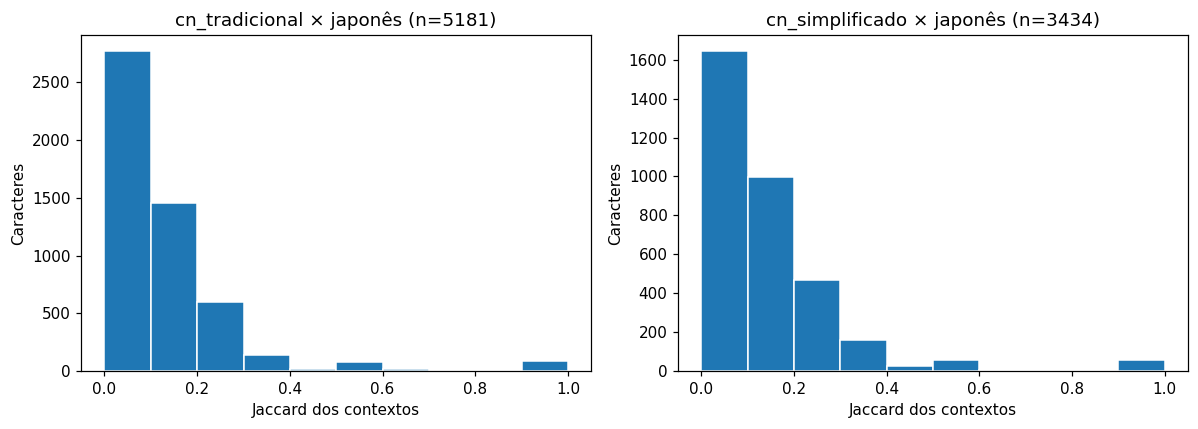

In [10]:
MIN_SUPPORT = 3
for variant, table in COMPARISONS.items():
    eligible = table[(table["grau_cn"] >= MIN_SUPPORT) & (table["grau_jp"] >= MIN_SUPPORT)]
    eligible = eligible.dropna(subset=["jaccard"])
    print(f"{variant}: {len(eligible)} caracteres com suporte ≥ {MIN_SUPPORT} nos dois idiomas.")
    if eligible.empty:
        print("Sem ranking com esse suporte na amostra atual.")
        continue
    print("Menor sobreposição ortográfica:")
    display(eligible.sort_values(["jaccard", "caractere"]).head(5).round(4))
    print("Maior sobreposição ortográfica:")
    display(eligible.sort_values(["jaccard", "caractere"], ascending=[False, True]).head(5).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (variant, table) in zip(axes, COMPARISONS.items()):
    values = table["jaccard"].dropna()
    ax.hist(values, bins=[i / 10 for i in range(11)], edgecolor="white")
    ax.set(title=f"{variant} × japonês (n={len(values)})", xlabel="Jaccard dos contextos", ylabel="Caracteres")
fig.tight_layout()
save_figure(fig, "jaccard_contextos")
plt.show()

## 10. Inspeção de palavras e definições

Troque `CHAR_TO_INSPECT` para investigar os rankings. A tabela mostra exemplos lexicais
reais; as traduções e os sentidos foram agrupados por grafia e não devem ser tratados como
pares de tradução. Nenhum limiar de Jaccard identifica automaticamente um falso cognato.

In [11]:
table = COMPARISONS["cn_tradicional"].dropna(subset=["jaccard"])
CHAR_TO_INSPECT = table.sort_values(["grau_cn", "grau_jp", "caractere"], ascending=[False, False, True]).iloc[0]["caractere"] if not table.empty else None


def inspect_character(char, limit=5):
    rows = []
    for name, graph in GRAPHS.items():
        node = "CHAR:" + char
        if node not in graph:
            continue
        for word in sorted(graph.neighbors(node))[:limit]:
            data = graph.nodes[word]
            rows.append({"rede": name, "palavra": data["label"],
                         "leitura": data["reading"], "definicao": data["definition"]})
    return pd.DataFrame(rows, columns=["rede", "palavra", "leitura", "definicao"])


if CHAR_TO_INSPECT:
    print("Caractere inspecionado:", CHAR_TO_INSPECT)
    display(inspect_character(CHAR_TO_INSPECT))
else:
    print("Sem caractere com contexto comparável nesta amostra.")

Caractere inspecionado: 不


,rede,palavra,leitura,definicao
0,cn_tradicional,一丁不識,yi1 ding1 bu4 shi2,(idiom) illiterate
1,cn_tradicional,一不做，二不休,"yi1 bu4 zuo4 , er4 bu4 xiu1","lit. either don't do it, or don't rest (idiom)..."
2,cn_tradicional,一不小心,yi1 bu4 xiao3 xin1,to be a little bit careless; to have a moment ...
3,cn_tradicional,一介不取,yi1 jie4 bu4 qu3,to not even take a penny (as a bribe)
4,cn_tradicional,一代不如一代,yi1 dai4 bu4 ru2 yi1 dai4,to be getting worse with each generation
5,cn_simplificado,一丁不识,yi1 ding1 bu4 shi2,(idiom) illiterate
6,cn_simplificado,一不做，二不休,"yi1 bu4 zuo4 , er4 bu4 xiu1","lit. either don't do it, or don't rest (idiom)..."
7,cn_simplificado,一不小心,yi1 bu4 xiao3 xin1,to be a little bit careless; to have a moment ...
8,cn_simplificado,一丝不挂,yi1 si1 bu4 gua4,not wearing one thread (idiom); absolutely nak...
9,cn_simplificado,一丝不苟,yi1 si1 bu4 gou3,not one thread loose (idiom); strictly accordi...


## 11. Visualizações comparativas

As análises anteriores usam todos os dados definidos por `USE_SAMPLE`. A partir daqui,
escolhemos **somente os caracteres desenhados**, sem filtrar as redes ou métricas anteriores.
As palavras ligadas a esses pontos contêm literalmente o mesmo Han/Kanji; significado,
pronúncia e tradução não são critérios para incluir um caractere compartilhado.

Os desenhos também limitam palavras por caractere, para legibilidade. Isso não é uma amostra
para inferência. As figuras são salvas em `resultados/figuras/`; pares simplificado/tradicional
continuam sendo correspondências da mesma entrada do CC-CEDICT.

### 11.1. Seleção explícita dos caracteres compartilhados

Controle incorporado de `LOTUS_top_frequency_para_manual.ipynb`, versão alternativa do grupo:

- `top_frequency`: ordena pela menor contagem de palavras nos dois idiomas, depois pela soma
  dessas contagens e pelo caractere. O nome usa **grau no dicionário**, não frequência de uso.
- `random`: sorteia até `SHARED_CHAR_COUNT` caracteres compartilhados com semente própria.
- `manual`: mantém a ordem e remove duplicatas das listas `MANUAL_SHARED_CHARS_TRAD` e
  `MANUAL_SHARED_CHARS_SIMP`. Caracteres ausentes de um dos lados são avisados e omitidos.
  Nesse modo, a lista inteira define a seleção; `SHARED_CHAR_COUNT` controla apenas as sugestões.

**Como fixar um ranking:** execute com `top_frequency`, copie as duas listas Python impressas
para a configuração e mude para `manual`. Os gráficos estáticos e interativos usam a mesma
seleção explícita, inclusive quando a lista manual tem uma ordem diferente do ranking.
`COMPARE_CHARS` e `INTERACTIVE_MAX_CHARS` são limites de desenho, configurados em 18; se
reduzi-los, cada desenho mostrará somente o início da lista selecionada.

Uma seleção manual fixa o recorte visual, não os graus: eles podem mudar com os dados ou
com `USE_SAMPLE`. As listas, sugestões e contagens são salvas em `resultados/selecao_caracteres.json`.
Não há avaliação semântica manual nesta etapa.

In [12]:
def select_shared_characters(table, mode, limit, manual_chars, seed):
    """Seleciona formas Unicode compartilhadas usando os graus já calculados."""
    if not isinstance(limit, int) or limit < 1:
        raise ValueError("SHARED_CHAR_COUNT deve ser um inteiro positivo.")
    ranked = table.assign(
        suporte_equilibrado=table[["grau_cn", "grau_jp"]].min(axis=1),
        suporte_total=table["grau_cn"] + table["grau_jp"],
    ).sort_values(["suporte_equilibrado", "suporte_total", "caractere"],
                  ascending=[False, False, True])
    available = set(ranked["caractere"])
    missing = []
    if mode == "top_frequency":
        selected = ranked["caractere"].head(limit).tolist()
    elif mode == "random":
        selected = sorted(random.Random(seed).sample(sorted(available), min(limit, len(available))))
    elif mode == "manual":
        manual = list(dict.fromkeys(normalize(str(char)) for char in manual_chars if str(char).strip()))
        selected = [char for char in manual if char in available]
        missing = [char for char in manual if char not in available]
    else:
        raise ValueError("SHARED_CHAR_MODE deve ser 'top_frequency', 'random' ou 'manual'.")
    return selected, ranked, missing


SELECTED_SHARED_CHARS = {}
selection_record = {"modo": SHARED_CHAR_MODE, "limite": SHARED_CHAR_COUNT,
                    "seed": SHARED_CHAR_SEED, "dados": MODE, "comparacoes": {}}
for variant, manual_chars, variable in (
    ("cn_tradicional", MANUAL_SHARED_CHARS_TRAD, "MANUAL_SHARED_CHARS_TRAD"),
    ("cn_simplificado", MANUAL_SHARED_CHARS_SIMP, "MANUAL_SHARED_CHARS_SIMP"),
):
    table = COMPARISONS[variant]
    selected, ranked, missing = select_shared_characters(
        table, SHARED_CHAR_MODE, SHARED_CHAR_COUNT, manual_chars, SHARED_CHAR_SEED)
    SELECTED_SHARED_CHARS[variant] = selected
    suggested = ranked["caractere"].head(SHARED_CHAR_COUNT).tolist()
    counts = table.set_index("caractere").reindex(selected).reset_index()
    print(f"\n{variant} × japonês — modo {SHARED_CHAR_MODE}: {len(selected)} caracteres: {selected}")
    if missing:
        print("Caracteres manuais ausentes em um dos idiomas, omitidos:", missing)
    print("Sugestão top_frequency pronta para copiar:")
    print(variable + " = " + repr(suggested))
    display(counts[["caractere", "grau_cn", "grau_jp"]])
    selection_record["comparacoes"][variant] = {
        "disponiveis": len(table), "selecionados": selected, "ausentes": missing,
        "top_frequency": suggested,
        "contagens": counts[["caractere", "grau_cn", "grau_jp"]].to_dict("records"),
    }
selected_shared_chars_trad = SELECTED_SHARED_CHARS["cn_tradicional"]
selected_shared_chars_simp = SELECTED_SHARED_CHARS["cn_simplificado"]
(RESULTS_DIR / "selecao_caracteres.json").write_text(
    json.dumps(selection_record, ensure_ascii=False, indent=2), encoding="utf-8")


cn_tradicional × japonês — modo manual: 18 caracteres: ['言', '子', '見', '化', '手', '方', '人', '語', '動', '上', '式', '通', '間', '馬', '無', '行', '生', '線']
Sugestão top_frequency pronta para copiar:
MANUAL_SHARED_CHARS_TRAD = ['子', '大', '人', '不', '一', '山', '水', '中', '心', '生', '頭', '無', '地', '天', '自', '性', '小', '家']


,caractere,grau_cn,grau_jp
0,言,358,1757
1,子,1827,3295
2,見,289,1336
3,化,651,1881
4,手,633,2317
5,方,400,1128
6,人,1746,3507
7,語,481,1530
8,動,694,1852
9,上,637,2144



cn_simplificado × japonês — modo manual: 18 caracteres: ['言', '子', '化', '手', '方', '人', '上', '式', '通', '行', '来', '生', '切', '小', '部', '字', '如', '天']
Sugestão top_frequency pronta para copiar:
MANUAL_SHARED_CHARS_SIMP = ['子', '大', '人', '不', '一', '国', '山', '水', '学', '中', '心', '生', '地', '天', '自', '性', '小', '家']


,caractere,grau_cn,grau_jp
0,言,358,1757
1,子,1818,3295
2,化,651,1881
3,手,631,2317
4,方,400,1128
5,人,1745,3507
6,上,636,2144
7,式,300,901
8,通,443,1225
9,行,640,1992


5026

In [13]:
# Visualizações comparativas com idiomas identificados, cores e layout em colunas.
# A seleção de caracteres é definida na seção 11.1; as redes completas permanecem em G_*.

COMPARE_CHARS = 18          # quantidade de caracteres compartilhados exibidos
WORDS_PER_CHAR_COMPARE = 2  # quantidade máxima de palavras por caractere e idioma
PAIRS_TO_SHOW = 12          # pares distintos na comparação simplificado/tradicional

COLOR_LEFT = "#9EC9FF"      # palavras do idioma/variante à esquerda
COLOR_CHAR = "#B8E0D2"      # caracteres compartilhados
COLOR_RIGHT = "#FFCC99"     # palavras do idioma/variante à direita
EDGE_LEFT = "#6495C8"
EDGE_RIGHT = "#D18A4B"


def _word_neighbors(graph, char_node, prefixes):
    """Vizinhos de um caractere que são palavras de um ou mais idiomas."""
    return [n for n in graph.neighbors(char_node) if n.startswith(prefixes)]


def _display_node_label(node, prefixes):
    if node.startswith("CHAR:"):
        return node[len("CHAR:"):]
    for prefix in prefixes:
        if node.startswith(prefix):
            return node[len(prefix):]
    return node


def plot_language_comparison(graph, title, left_name, left_prefixes,
                             right_name, right_prefixes,
                             max_chars=COMPARE_CHARS,
                             words_per_char=WORDS_PER_CHAR_COMPARE, selected_chars=None):
    """Grafo em três colunas: palavras à esquerda, caracteres no centro, palavras à direita."""
    left_prefixes = tuple(left_prefixes)
    right_prefixes = tuple(right_prefixes)

    ranked_chars = []
    for node, data in graph.nodes(data=True):
        if data.get("bipartite") != "character":
            continue
        left_words = _word_neighbors(graph, node, left_prefixes)
        right_words = _word_neighbors(graph, node, right_prefixes)
        # Só comparar caracteres que realmente aparecem nos dois lados.
        if left_words and right_words:
            ranked_chars.append((node, left_words, right_words))

    ranked_chars.sort(
        key=lambda item: (
            min(len(item[1]), len(item[2])),
            len(item[1]) + len(item[2]),
            item[0]
        ),
        reverse=True
    )
    if selected_chars is None:
        chosen = ranked_chars[:max_chars]
    else:
        by_char = {graph.nodes[item[0]]["label"]: item for item in ranked_chars}
        chosen = [by_char[char] for char in selected_chars if char in by_char][:max_chars]
    if not chosen:
        print(f"Não foram encontrados caracteres compartilhados para: {title}")
        return

    # Coordenadas previsíveis em colunas, para que cada cor e idioma fique evidente.
    spacing = 1.35
    center_y = (len(chosen) - 1) * spacing / 2
    pos = {}
    chosen_nodes = set()
    left_y_suggestions = {}
    right_y_suggestions = {}
    char_nodes = []

    for idx, (char_node, left_words, right_words) in enumerate(chosen):
        y = center_y - idx * spacing
        pos[char_node] = (0.0, y)
        chosen_nodes.add(char_node)
        char_nodes.append(char_node)

        # Seleciona palavras com mais ligações primeiro; isso tende a mostrar palavras
        # que ilustram melhor o uso dos caracteres e reduz a chance de grupos vazios.
        left_words = sorted(left_words, key=lambda n: (-graph.degree(n), graph.nodes[n].get("label", n)))[:words_per_char]
        right_words = sorted(right_words, key=lambda n: (-graph.degree(n), graph.nodes[n].get("label", n)))[:words_per_char]

        for words, suggestions in ((left_words, left_y_suggestions), (right_words, right_y_suggestions)):
            if len(words) == 1:
                offsets = [0.0]
            else:
                offsets = [((j / (len(words) - 1)) - 0.5) * 0.78 for j in range(len(words))]
            for word_node, offset in zip(words, offsets):
                chosen_nodes.add(word_node)
                suggestions.setdefault(word_node, []).append(y + offset)

    # Mantém a ordem sugerida, com espaçamento uniforme para evitar rótulos sobrepostos.
    for x, suggestions in ((-3.7, left_y_suggestions), (3.7, right_y_suggestions)):
        ordered = sorted(suggestions, key=lambda n: (-sum(suggestions[n]) / len(suggestions[n]), n))
        for i, node in enumerate(ordered):
            y = 0 if len(ordered) == 1 else center_y + 0.4 - i * (2 * center_y + 0.8) / (len(ordered) - 1)
            pos[node] = (x, y)

    sample = graph.subgraph(chosen_nodes).copy()
    left_nodes = [n for n in sample.nodes if n.startswith(left_prefixes)]
    right_nodes = [n for n in sample.nodes if n.startswith(right_prefixes)]
    center_nodes = [n for n in sample.nodes if n.startswith("CHAR:")]
    left_edges, right_edges = [], []
    for u, v in sample.edges():
        if u.startswith(left_prefixes) or v.startswith(left_prefixes):
            left_edges.append((u, v))
        elif u.startswith(right_prefixes) or v.startswith(right_prefixes):
            right_edges.append((u, v))

    fig_height = max(9.5, len(chosen) * 0.68)
    fig, ax = plt.subplots(figsize=(17, fig_height))
    nx.draw_networkx_edges(sample, pos, edgelist=left_edges, edge_color=EDGE_LEFT,
                           alpha=0.48, width=1.0, ax=ax)
    nx.draw_networkx_edges(sample, pos, edgelist=right_edges, edge_color=EDGE_RIGHT,
                           alpha=0.48, width=1.0, ax=ax)
    nx.draw_networkx_nodes(sample, pos, nodelist=left_nodes, node_color=COLOR_LEFT,
                           node_size=520, edgecolors="#35516E", linewidths=0.7, ax=ax)
    nx.draw_networkx_nodes(sample, pos, nodelist=center_nodes, node_color=COLOR_CHAR,
                           node_size=1050, edgecolors="#386B59", linewidths=1.2, ax=ax)
    nx.draw_networkx_nodes(sample, pos, nodelist=right_nodes, node_color=COLOR_RIGHT,
                           node_size=520, edgecolors="#88572B", linewidths=0.7, ax=ax)

    # Rótulos manuais para usar a fonte CJK também nos nós e manter a leitura nítida.
    for node, (x, y) in pos.items():
        label = _display_node_label(node, left_prefixes + right_prefixes)
        fontsize = 13 if node.startswith("CHAR:") else 8.5
        if node.startswith("CHAR:"):
            label_color = COLOR_CHAR
        elif node.startswith(left_prefixes):
            label_color = COLOR_LEFT
        else:
            label_color = COLOR_RIGHT
        ax.text(x, y, label, fontproperties=cjk_font, fontsize=fontsize,
                ha="center", va="center", color="#17212B",
                bbox=dict(facecolor=label_color, edgecolor="none", alpha=0.94, pad=1.0),
                zorder=5)

    top_y = center_y + 1.25
    ax.text(-3.7, top_y, left_name, ha="center", va="bottom", fontsize=12,
            fontweight="bold", wrap=True)
    ax.text(0, top_y, "CARACTERES COMPARTILHADOS", ha="center", va="bottom",
            fontsize=12, fontweight="bold")
    ax.text(3.7, top_y, right_name, ha="center", va="bottom", fontsize=12,
            fontweight="bold", wrap=True)

    from matplotlib.lines import Line2D
    legend_items = [
        Line2D([0], [0], marker="o", color="w", label=left_name,
               markerfacecolor=COLOR_LEFT, markeredgecolor="#35516E", markersize=10),
        Line2D([0], [0], marker="o", color="w", label="Caractere Han/Kanji",
               markerfacecolor=COLOR_CHAR, markeredgecolor="#386B59", markersize=10),
        Line2D([0], [0], marker="o", color="w", label=right_name,
               markerfacecolor=COLOR_RIGHT, markeredgecolor="#88572B", markersize=10),
    ]
    ax.legend(handles=legend_items, loc="lower center", bbox_to_anchor=(0.5, -0.035),
              ncol=3, frameon=False, fontsize=9)
    ax.set_title(title, fontsize=16, pad=22, fontweight="bold")
    ax.set_xlim(-5.7, 5.7)
    ax.set_ylim(-center_y - 1.3, top_y + 0.7)
    ax.axis("off")
    fig.tight_layout()
    save_figure(fig, title)
    plt.show()
    print(f"{title}: {len(chosen)} caracteres compartilhados; "
          f"{len(left_nodes)} palavras à esquerda; {len(right_nodes)} palavras à direita; "
          f"{sample.number_of_edges()} ligações na amostra visual.")


def plot_simplified_traditional_pairs(df, max_pairs=PAIRS_TO_SHOW):
    """Mostra pares reais do CC-CEDICT em duas colunas alinhadas por entrada do dicionário."""
    pairs = df[["simplified", "traditional"]].copy()
    pairs = pairs.dropna()
    pairs["simplified"] = pairs["simplified"].astype(str).str.strip()
    pairs["traditional"] = pairs["traditional"].astype(str).str.strip()
    pairs = pairs[(pairs["simplified"] != "") & (pairs["traditional"] != "")]
    pairs = pairs[pairs["simplified"] != pairs["traditional"]]
    pairs = pairs.drop_duplicates(subset=["simplified", "traditional"]).reset_index(drop=True)

    if pairs.empty:
        print("Nenhum par diferente entre chinês simplificado e tradicional foi encontrado.")
        return

    # Amostra distribuída pelo dicionário em vez de usar apenas as primeiras entradas.
    n = min(max_pairs, len(pairs))
    if n == 1:
        selected_indices = [0]
    else:
        selected_indices = [round(i * (len(pairs) - 1) / (n - 1)) for i in range(n)]
    pairs = pairs.iloc[selected_indices].reset_index(drop=True)

    pair_graph = nx.Graph()
    pos = {}
    labels = {}
    for i, row in pairs.iterrows():
        simp_node = f"SIMP_PAIR_{i}"
        trad_node = f"TRAD_PAIR_{i}"
        y = (len(pairs) - 1) / 2 - i
        pair_graph.add_node(simp_node, language="chinese_simplified")
        pair_graph.add_node(trad_node, language="chinese_traditional")
        pair_graph.add_edge(simp_node, trad_node, relation="same_dictionary_entry")
        pos[simp_node] = (-1.9, y)
        pos[trad_node] = (1.9, y)
        labels[simp_node] = row["simplified"]
        labels[trad_node] = row["traditional"]

    fig, ax = plt.subplots(figsize=(14, max(9, len(pairs) * 0.47)))
    nx.draw_networkx_edges(pair_graph, pos, edge_color="#8B8B8B", alpha=0.68,
                           width=1.2, ax=ax)
    simp_nodes = [n for n in pair_graph.nodes if n.startswith("SIMP_PAIR_")]
    trad_nodes = [n for n in pair_graph.nodes if n.startswith("TRAD_PAIR_")]
    nx.draw_networkx_nodes(pair_graph, pos, nodelist=simp_nodes, node_color=COLOR_LEFT,
                           node_size=850, edgecolors="#35516E", linewidths=0.8, ax=ax)
    nx.draw_networkx_nodes(pair_graph, pos, nodelist=trad_nodes, node_color=COLOR_RIGHT,
                           node_size=850, edgecolors="#88572B", linewidths=0.8, ax=ax)
    for node, (x, y) in pos.items():
        label_color = COLOR_LEFT if node.startswith("SIMP_PAIR_") else COLOR_RIGHT
        ax.text(x, y, labels[node], fontproperties=cjk_font, fontsize=10,
                ha="center", va="center", color="#17212B",
                bbox=dict(facecolor=label_color, edgecolor="none", alpha=0.95, pad=1.0),
                zorder=5)
    top_y = (len(pairs) - 1) / 2 + 0.9
    ax.text(-1.9, top_y, "简体中文 — CHINÊS SIMPLIFICADO", ha="center", va="bottom",
            fontsize=11, fontweight="bold", fontproperties=cjk_font)
    ax.text(1.9, top_y, "繁體中文 — CHINÊS TRADICIONAL", ha="center", va="bottom",
            fontsize=11, fontweight="bold", fontproperties=cjk_font)
    ax.set_title("Comparação de formas correspondentes no CC-CEDICT", fontsize=15,
                 pad=20, fontweight="bold")
    ax.set_xlim(-4.3, 4.3)
    ax.set_ylim(-0.9, top_y + 0.8)
    ax.axis("off")
    fig.tight_layout()
    save_figure(fig, "pares_simplificado_tradicional")
    plt.show()
    print(f"Chinês simplificado × tradicional: {len(pairs)} pares distintos exibidos "
          f"(cada linha conecta duas formas da mesma entrada do CC-CEDICT).")

Resumo das redes completas carregadas:
  Caracteres no japonês: 6042


  Caracteres no chinês tradicional: 11686


  Caracteres no chinês simplificado: 10771


  Compartilhados japonês/tradicional: 5353


  Compartilhados japonês/simplificado: 3599


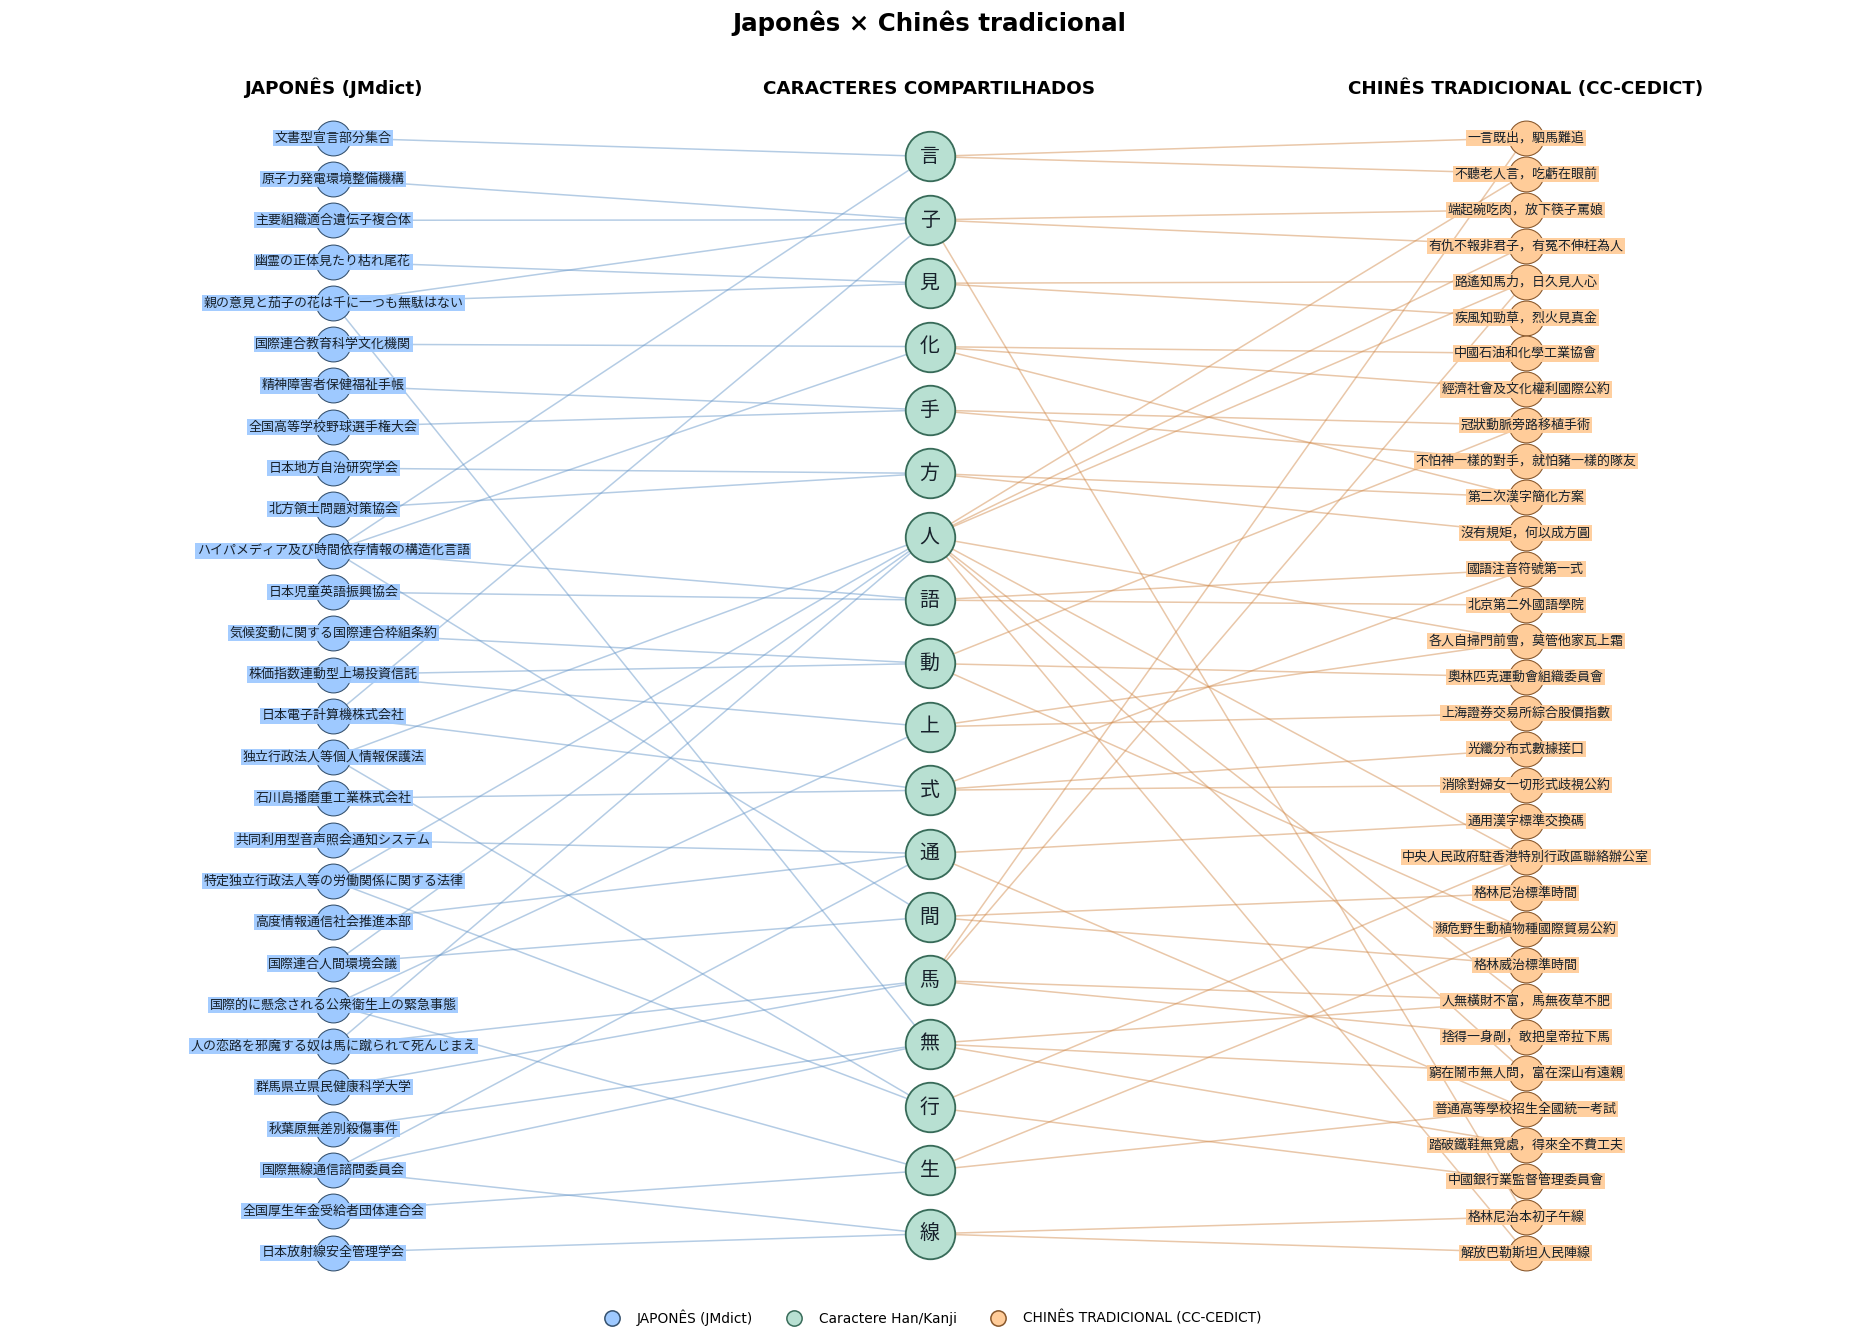

Japonês × Chinês tradicional: 18 caracteres compartilhados; 28 palavras à esquerda; 32 palavras à direita; 91 ligações na amostra visual.


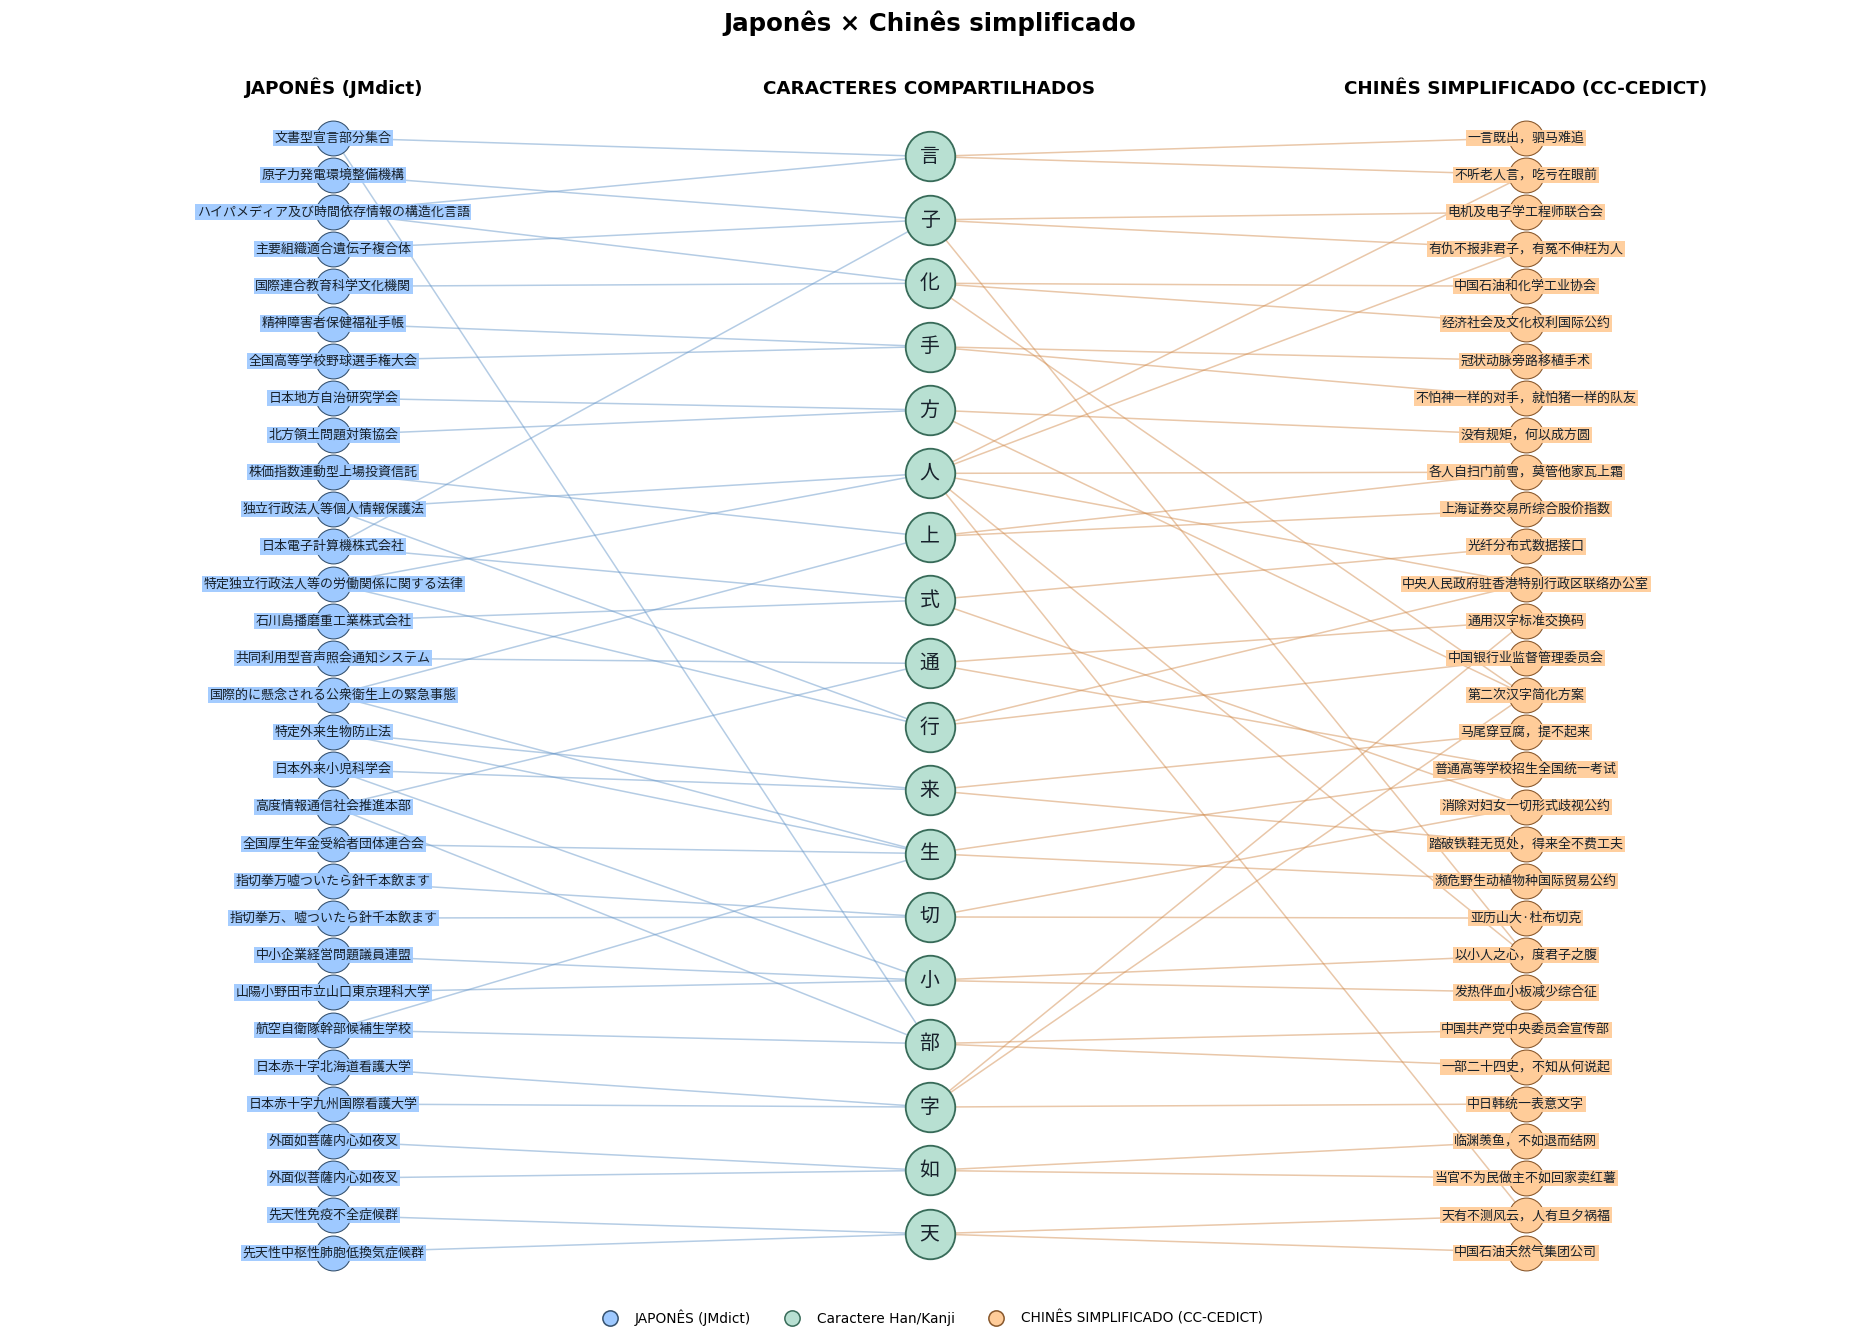

Japonês × Chinês simplificado: 18 caracteres compartilhados; 31 palavras à esquerda; 31 palavras à direita; 84 ligações na amostra visual.


/tmp/ipykernel_5802/675732067.py:232: UserWarning: Glyph 201529 (\N{CJK UNIFIED IDEOGRAPH-31339}) missing from font(s) Noto Sans CJK JP.
  fig.tight_layout()
/tmp/ipykernel_5802/3871077270.py:61: UserWarning: Glyph 201529 (\N{CJK UNIFIED IDEOGRAPH-31339}) missing from font(s) Noto Sans CJK JP.
  fig.savefig(FIGURES_DIR / f"{slug}.png", dpi=150, bbox_inches="tight")


/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 201529 (\N{CJK UNIFIED IDEOGRAPH-31339}) missing from font(s) Noto Sans CJK JP.
  fig.canvas.print_figure(bytes_io, **kw)


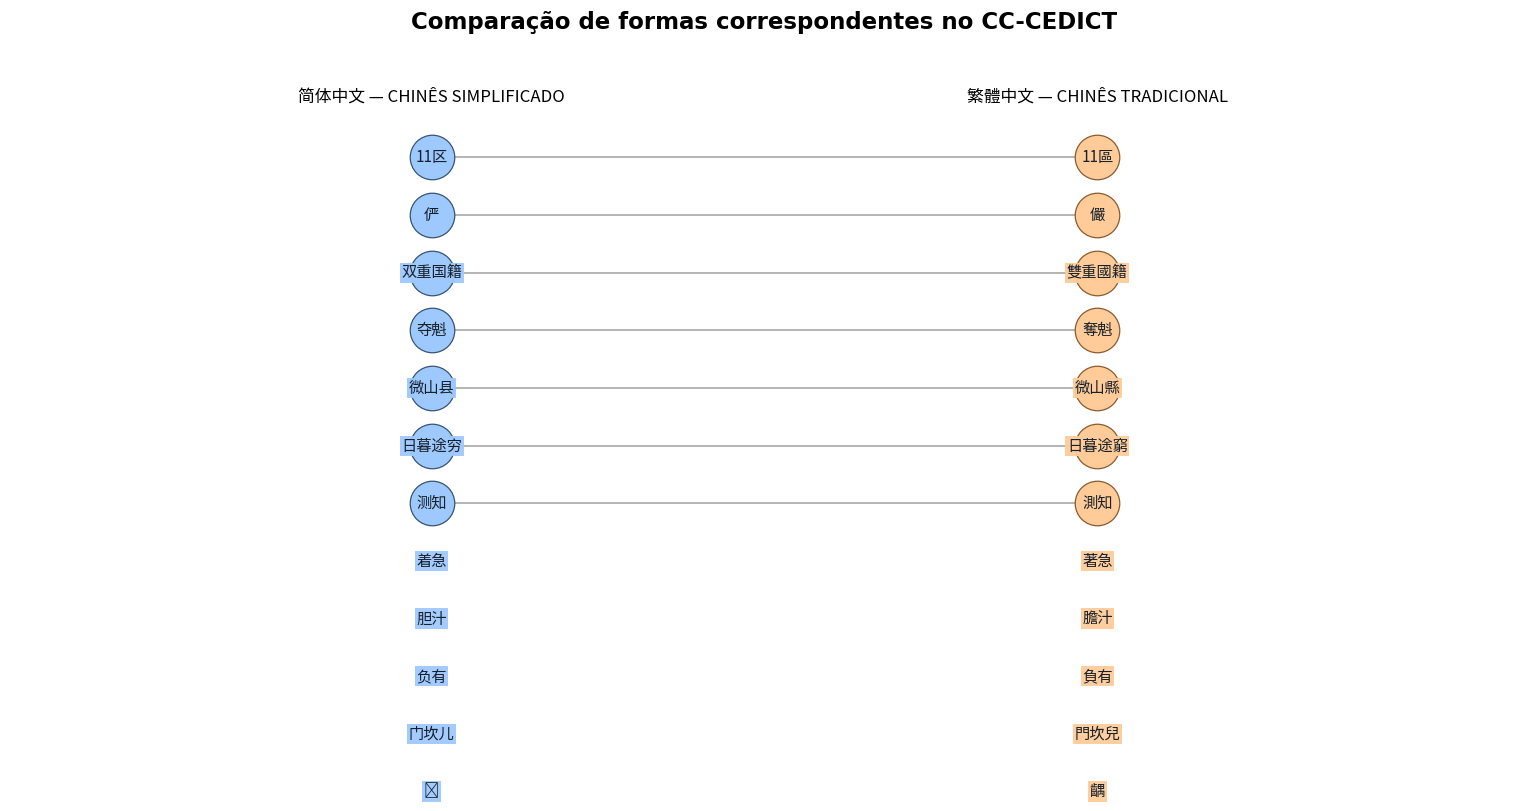

Chinês simplificado × tradicional: 12 pares distintos exibidos (cada linha conecta duas formas da mesma entrada do CC-CEDICT).


In [14]:
# Contagens antes dos desenhos: ajudam a distinguir volume de dados e limite visual.
def _chars_with_prefix(graph, prefixes):
    prefixes = tuple(prefixes)
    return {
        char_node
        for char_node, data in graph.nodes(data=True)
        if data.get("bipartite") == "character"
        and any(neighbor.startswith(prefixes) for neighbor in graph.neighbors(char_node))
    }

print("Resumo das redes completas carregadas:")
print(f"  Caracteres no japonês: {len(_chars_with_prefix(G_jp, ('JP_WORD:',)))}")
print(f"  Caracteres no chinês tradicional: {len(_chars_with_prefix(G_cn_trad, ('CN_TRAD_WORD:',)))}")
print(f"  Caracteres no chinês simplificado: {len(_chars_with_prefix(G_cn_simp, ('CN_WORD:',)))}")
print(f"  Compartilhados japonês/tradicional: {len(_chars_with_prefix(G_jp, ('JP_WORD:',)) & _chars_with_prefix(G_cn_trad, ('CN_TRAD_WORD:',)))}")
print(f"  Compartilhados japonês/simplificado: {len(_chars_with_prefix(G_jp, ('JP_WORD:',)) & _chars_with_prefix(G_cn_simp, ('CN_WORD:',)))}")

plot_language_comparison(
    G_jp_vs_trad,
    "Japonês × Chinês tradicional",
    "JAPONÊS (JMdict)", ["JP_WORD:"],
    "CHINÊS TRADICIONAL (CC-CEDICT)", ["CN_TRAD_WORD:"],
    selected_chars=selected_shared_chars_trad
)

plot_language_comparison(
    G_jp_vs_simp,
    "Japonês × Chinês simplificado",
    "JAPONÊS (JMdict)", ["JP_WORD:"],
    "CHINÊS SIMPLIFICADO (CC-CEDICT)", ["CN_WORD:"],
    selected_chars=selected_shared_chars_simp
)

plot_simplified_traditional_pairs(df_cn_used)

## 12. Grafos interativos

As três redes são exibidas abaixo por padrão (`INTERACTIVE_INLINE = True`) e também
salvas em `resultados/grafos/`, que faz parte do repositório. Os HTMLs são autocontidos:
baixe e abra no navegador para arrastar os nós, usar o zoom e consultar as definições.

Para interagir dentro do notebook, execute esta seção no Colab ou em um Jupyter confiável.
A visualização de notebooks no GitHub não executa JavaScript; use o link do Colab ou os
arquivos HTML para interação. Defina `INTERACTIVE_INLINE = False` apenas se quiser salvar
os HTMLs sem embuti-los na saída.

No terceiro grafo, as arestas roxas unem as formas simplificada/tradicional da mesma entrada.
Esse grafo tem relações entre palavras e serve **somente para visualização**: as estatísticas
e projeções foram calculadas nas redes bipartidas puras, antes dessas arestas.

As duas comparações com japonês respeitam as listas da seção 11.1, também usadas nas
figuras estáticas. A comparação entre variantes chinesas mantém a seleção automática anterior.

In [15]:
# A correspondência entre variantes usa os nós já existentes, sem duplicar simplificadas.
G_cn_simp_vs_trad = nx.compose(G_cn_simp, G_cn_trad)
for simplified, traditional in df_cn_used[["simplified", "traditional"]].itertuples(index=False, name=None):
    left, right = "CN_WORD:" + simplified, "CN_TRAD_WORD:" + traditional
    if left in G_cn_simp_vs_trad and right in G_cn_simp_vs_trad:
        G_cn_simp_vs_trad.add_edge(left, right, relation="traditional_simplified_entry_pair")
assert len(G_cn_simp_vs_trad) == len(G_cn_simp) + len(G_cn_trad) - len(
    set(partition(G_cn_simp, "character")) & set(partition(G_cn_trad, "character")))

In [16]:
# Grafos interativos espalhados com PyVis.
# Arrastar = reposicionar nó | roda do mouse = zoom | passar o mouse = detalhes | clicar = destacar conexões.

from pyvis.network import Network
from IPython.display import display, HTML
import html as _html
import math as _math

# Ajustes de legibilidade/desempenho. Aumente gradualmente se o navegador suportar.
INTERACTIVE_MAX_CHARS = 18
INTERACTIVE_WORDS_PER_CHAR = 3
INTERACTIVE_HEIGHT = "760px"

# Paleta estável: a mesma variante mantém a mesma cor nos três grafos.
INTERACTIVE_COLORS = {
    "japanese": "#60A5FA",             # azul
    "chinese_traditional": "#FDBA74",  # laranja
    "chinese_simplified": "#86EFAC",   # verde
    "shared": "#DDD6FE",               # lilás: caractere Han/Kanji
}
INTERACTIVE_BORDERS = {
    "japanese": "#1D4ED8",
    "chinese_traditional": "#9A3412",
    "chinese_simplified": "#166534",
    "shared": "#7C3AED",
}
INTERACTIVE_LANGUAGE_NAMES = {
    "japanese": "Japonês (JMdict)",
    "chinese_traditional": "Chinês tradicional (CC-CEDICT)",
    "chinese_simplified": "Chinês simplificado (CC-CEDICT)",
    "shared": "Caractere Han/Kanji",
}


def _interactive_label(node, data):
    """Nome que aparece junto do nó na visualização."""
    label = data.get("label")
    if label is not None and str(label).strip():
        return str(label).strip()
    for prefix in ("JP_WORD:", "CN_TRAD_WORD:", "CN_WORD:"):
        if node.startswith(prefix):
            return node[len(prefix):]
    if node.startswith("CHAR:"):
        return node[len("CHAR:"):]
    return str(node)


def _interactive_ranked_chars(graph, left_prefixes, right_prefixes):
    """Seleciona caracteres conectados a palavras dos dois lados da comparação."""
    left_prefixes = tuple(left_prefixes)
    right_prefixes = tuple(right_prefixes)
    ranked = []
    for char_node, attrs in graph.nodes(data=True):
        if attrs.get("bipartite") != "character" or not str(char_node).startswith("CHAR:"):
            continue
        left_words = [n for n in graph.neighbors(char_node) if n.startswith(left_prefixes)]
        right_words = [n for n in graph.neighbors(char_node) if n.startswith(right_prefixes)]
        if left_words and right_words:
            ranked.append((char_node, left_words, right_words))
    ranked.sort(
        key=lambda item: (min(len(item[1]), len(item[2])), len(item[1]) + len(item[2]), item[0]),
        reverse=True,
    )
    return ranked


def _interactive_sample(graph, left_prefixes, right_prefixes,
                        max_chars=INTERACTIVE_MAX_CHARS,
                        words_per_char=INTERACTIVE_WORDS_PER_CHAR, selected_chars=None):
    """Recorte visual: respeita a seleção explícita, quando fornecida, e limita palavras."""
    ranked = _interactive_ranked_chars(graph, left_prefixes, right_prefixes)
    if not ranked:
        return graph.subgraph([]).copy(), []

    if selected_chars is None:
        chosen_chars = ranked[:max_chars]
    else:
        by_char = {graph.nodes[item[0]]["label"]: item for item in ranked}
        chosen_chars = [by_char[char] for char in selected_chars if char in by_char][:max_chars]
    chosen_nodes = set()
    for char_node, left_words, right_words in chosen_chars:
        chosen_nodes.add(char_node)
        for words, prefixes in ((left_words, tuple(left_prefixes)), (right_words, tuple(right_prefixes))):
            # Prioriza palavras com mais ligações a caracteres, para revelar interseções entre palavras.
            words = sorted(
                words,
                key=lambda node: (-graph.degree(node), _interactive_label(node, graph.nodes[node]))
            )[:words_per_char]
            chosen_nodes.update(words)

    # Na comparação simplificado/tradicional, inclui a forma correspondente ligada pela mesma entrada.
    # Isso deixa explícito quando dois nós são variantes da mesma entrada do dicionário.
    for node in list(chosen_nodes):
        if node not in graph:
            continue
        for neighbor in graph.neighbors(node):
            relation = graph.edges[node, neighbor].get("relation", "")
            if relation == "traditional_simplified_entry_pair":
                chosen_nodes.add(neighbor)

    sample = graph.subgraph(chosen_nodes).copy()
    return sample, chosen_chars


def _interactive_detail_maps(sample):
    details = {"japanese": {}, "chinese_simplified": {}, "chinese_traditional": {}}
    for node, attrs in sample.nodes(data=True):
        language = attrs.get("language")
        if language not in details:
            continue
        text = f"Leitura: {attrs.get('reading', '')}. Definição: {attrs.get('definition', '')}"
        details[language][attrs["label"]] = [text]
    return details


def _interactive_node_title(node, attrs, full_graph, left_prefixes, right_prefixes, detail_maps):
    label = _interactive_label(node, attrs)
    language = attrs.get("language", "shared")
    language_name = INTERACTIVE_LANGUAGE_NAMES.get(language, str(language))
    chunks = [f"<b>{_html.escape(language_name)}</b>", f"Forma: {_html.escape(label)}"]

    if attrs.get("bipartite") == "character":
        left_count = sum(n.startswith(tuple(left_prefixes)) for n in full_graph.neighbors(node))
        right_count = sum(n.startswith(tuple(right_prefixes)) for n in full_graph.neighbors(node))
        chunks.append(f"Palavras ligadas no lado esquerdo: {left_count}")
        chunks.append(f"Palavras ligadas no lado direito: {right_count}")
    else:
        detail_key = language if language in detail_maps else None
        if detail_key:
            for detail in detail_maps[detail_key].get(label, []):
                if detail:
                    chunks.append(_html.escape(detail))
        count = sum(full_graph.nodes[n].get("bipartite") == "character" for n in full_graph.neighbors(node))
        chunks.append(f"Caracteres ligados na rede completa: {count}")
    return "<br>".join(chunks)


def _display_force_graph(graph, title, left_name, left_prefixes,
                         right_name, right_prefixes, selected_chars=None):
    left_prefixes = tuple(left_prefixes)
    right_prefixes = tuple(right_prefixes)
    sample, ranked_chars = _interactive_sample(
        graph, left_prefixes, right_prefixes,
        max_chars=INTERACTIVE_MAX_CHARS,
        words_per_char=INTERACTIVE_WORDS_PER_CHAR, selected_chars=selected_chars,
    )
    if sample.number_of_nodes() == 0:
        print(f"{title}: não foram encontrados caracteres conectando os dois lados com os dados atuais.")
        return

    net = Network(
        height=INTERACTIVE_HEIGHT,
        width="100%",
        directed=False,
        notebook=True,
        cdn_resources="in_line",
        bgcolor="#FFFFFF",
        font_color="#1F2937",
    )
    detail_maps = _interactive_detail_maps(sample)

    for node, attrs in sample.nodes(data=True):
        label = _interactive_label(node, attrs)
        language = attrs.get("language", "shared")
        color = INTERACTIVE_COLORS.get(language, "#D1D5DB")
        border = INTERACTIVE_BORDERS.get(language, "#6B7280")
        is_character = attrs.get("bipartite") == "character"
        full_degree = graph.degree(node) if node in graph else sample.degree(node)
        size = (18 + min(13, int(_math.log1p(full_degree) * 2.2))) if is_character else (12 + min(5, sample.degree(node)))
        font_size = 18 if is_character else 12
        net.add_node(
            str(node),
            label=label,
            title=_interactive_node_title(
                node, attrs, graph, left_prefixes, right_prefixes, detail_maps
            ),
            color={"background": color, "border": border, "highlight": {"background": "#FDE68A", "border": "#111827"}},
            borderWidth=1.6,
            size=size,
            shape="diamond" if is_character else "dot",
            font={"size": font_size, "face": "Arial, sans-serif", "strokeWidth": 2, "strokeColor": "#FFFFFF"},
            margin=7,
            shadow={"enabled": True, "size": 4, "x": 1, "y": 1},
        )

    for u, v, edge_attrs in sample.edges(data=True):
        relation = edge_attrs.get("relation", "contains_character")
        if relation == "traditional_simplified_entry_pair":
            edge_color = "#9333EA"
            edge_title = "Duas formas correspondentes na mesma entrada do CC-CEDICT"
            width = 2.8
            dashes = False
        else:
            word_node = u if sample.nodes[u].get("bipartite") == "word" else v
            word_language = sample.nodes[word_node].get("language", "shared")
            edge_color = INTERACTIVE_COLORS.get(word_language, "#9CA3AF")
            char_node = v if word_node == u else u
            edge_title = f"{_html.escape(_interactive_label(word_node, sample.nodes[word_node]))} contém o caractere {_html.escape(_interactive_label(char_node, sample.nodes[char_node]))}"
            width = 1.5
            dashes = False
        net.add_edge(
            str(u), str(v), color=edge_color, title=edge_title,
            width=width, dashes=dashes,
        )

    net.set_options(r"""var options = {
      "nodes": {"scaling": {"min": 10, "max": 32}, "font": {"size": 12}, "labelHighlightBold": true},
      "edges": {"smooth": {"enabled": true, "type": "dynamic"}, "selectionWidth": 2.5, "hoverWidth": 1.5},
      "layout": {"randomSeed": 42, "improvedLayout": true},
      "interaction": {"hover": true, "tooltipDelay": 120, "navigationButtons": true,
                      "keyboard": {"enabled": true, "bindToWindow": false},
                      "dragNodes": true, "dragView": true, "zoomView": true,
                      "selectConnectedEdges": true, "hideEdgesOnDrag": false},
      "physics": {"enabled": true, "solver": "barnesHut",
                   "barnesHut": {"gravitationalConstant": -18000, "centralGravity": 0.18,
                                 "springLength": 105, "springConstant": 0.035,
                                 "damping": 0.38, "avoidOverlap": 0.8},
                   "stabilization": {"enabled": true, "iterations": 650, "updateInterval": 30}}
    }""")

    # Legenda específica deste grafo: deixa claro quais idiomas estão realmente presentes.
    def _prefix_language(prefixes):
        prefixes = tuple(prefixes)
        if any(p.startswith("JP_WORD") for p in prefixes):
            return "japanese"
        if any(p.startswith(("CN_SIMP_PAIR", "CN_WORD")) for p in prefixes):
            return "chinese_simplified"
        if any(p.startswith("CN_TRAD_WORD") for p in prefixes):
            return "chinese_traditional"
        return "shared"

    left_language = _prefix_language(left_prefixes)
    right_language = _prefix_language(right_prefixes)
    palette_html = (
        f'<span style="color:{INTERACTIVE_COLORS[left_language]};font-weight:700">● {_html.escape(left_name)}</span> &nbsp; '
        f'<span style="color:{INTERACTIVE_COLORS["shared"]};font-weight:700">◆ Caractere Han/Kanji</span> &nbsp; '
        f'<span style="color:{INTERACTIVE_COLORS[right_language]};font-weight:700">● {_html.escape(right_name)}</span>'
    )
    has_pair_edges = any(data.get("relation") == "traditional_simplified_entry_pair" for _, _, data in sample.edges(data=True))
    if has_pair_edges:
        palette_html += ' &nbsp; <span style="color:#9333EA;font-weight:700">━ Formas da mesma entrada do CC-CEDICT</span>'
    display(HTML(
        f'<div style="font-family:Arial,sans-serif;margin:10px 0 6px 0">'
        f'<h3 style="margin:4px 0">{_html.escape(title)}</h3>'
        f'<div style="font-size:13px;line-height:1.8">{palette_html}</div>'
        f'<div style="font-size:12px;color:#4B5563">Arraste os nós, use o zoom e passe o mouse para ver detalhes. '
        f'Amostra atual: {sample.number_of_nodes()} nós e {sample.number_of_edges()} arestas.</div></div>'
    ))

    # Iframe srcdoc isole o JavaScript de cada rede, para que as três visualizações funcionem juntas.
    html_doc = net.generate_html(notebook=True)
    escaped_doc = _html.escape(html_doc, quote=True)
    iframe = (
        f'<iframe title="{_html.escape(title, quote=True)}" '
        f'width="100%" height="{INTERACTIVE_HEIGHT}" '
        'style="border:1px solid #D1D5DB;border-radius:8px;background:#FFFFFF" '
        'sandbox="allow-scripts" '
        f'srcdoc="{escaped_doc}"></iframe>'
    )
    folder = GRAPHS_DIR
    folder.mkdir(parents=True, exist_ok=True)
    filename = "japones_tradicional" if "japonês × chinês tradicional" in title else (
        "japones_simplificado" if "japonês × chinês simplificado" in title else "simplificado_tradicional")
    (folder / f"{filename}.html").write_text(html_doc, encoding="utf-8")
    if INTERACTIVE_INLINE:
        display({"text/html": iframe}, raw=True)
    print(f"HTML salvo: {folder / (filename + '.html')}")
    chars_shown = sum(1 for n, data in sample.nodes(data=True) if data.get("bipartite") == "character")
    print(f"{title}: {chars_shown} nós de caracteres; {sample.number_of_nodes()} nós totais; {sample.number_of_edges()} arestas.")

In [17]:
# 1. Japonês × chinês tradicional
_display_force_graph(
    G_jp_vs_trad,
    "Grafo interativo — japonês × chinês tradicional",
    "JAPONÊS", ["JP_WORD:"],
    "CHINÊS TRADICIONAL", ["CN_TRAD_WORD:"],
    selected_chars=selected_shared_chars_trad,
)

# 2. Japonês × chinês simplificado
_display_force_graph(
    G_jp_vs_simp,
    "Grafo interativo — japonês × chinês simplificado",
    "JAPONÊS", ["JP_WORD:"],
    "CHINÊS SIMPLIFICADO", ["CN_WORD:"],
    selected_chars=selected_shared_chars_simp,
)

# 3. Chinês simplificado × tradicional: inclui a ligação direta entre formas da mesma entrada.
_display_force_graph(
    G_cn_simp_vs_trad,
    "Grafo interativo — chinês simplificado × chinês tradicional",
    "CHINÊS SIMPLIFICADO", ["CN_WORD:"],
    "CHINÊS TRADICIONAL", ["CN_TRAD_WORD:"],
)

<iframe title="Grafo interativo — japonês × chinês tradicional" width="100%" height="760px" style="border:1px solid #D1D5DB;border-radius:8px;background:#FFFFFF" sandbox="allow-scripts" srcdoc="<html>
 <head>
 <meta charset="utf-8">
 
 <script>function neighbourhoodHighlight(params) {
 // console.log("in nieghbourhoodhighlight");
 allNodes = nodes.get({ returnType: "Object" });
 // originalNodes = JSON.parse(JSON.stringify(allNodes));
 // if something is selected:
 if (params.nodes.length > 0) {
 highlightActive = true;
 var i, j;
 var selectedNode = params.nodes[0];
 var degrees = 2;

 // mark all nodes as hard to read.
 for (let nodeId in allNodes) {
 // nodeColors[nodeId] = allNodes[nodeId].color;
 allNodes[nodeId].color = "rgba(200,200,200,0.5)";
 if (allNodes[nodeId].hiddenLabel === undefined) {
 allNodes[nodeId].hiddenLabel = allNodes[nodeId].label;
 allNodes[nodeId].label = undefined;
 }
 }
 var connectedNodes = network.getConnectedNodes(selectedNode);
 var allConnectedNodes = [];

 // get the second degree nodes
 for (i = 1; i < degrees; i++) {
 for (j = 0; j < connectedNodes.length; j++) {
 allConnectedNodes = allConnectedNodes.concat(
 network.getConnectedNodes(connectedNodes[j])
 );
 }
 }

 // all second degree nodes get a different color and their label back
 for (i = 0; i < allConnectedNodes.length; i++) {
 // allNodes[allConnectedNodes[i]].color = "pink";
 allNodes[allConnectedNodes[i]].color = "rgba(150,150,150,0.75)";
 if (allNodes[allConnectedNodes[i]].hiddenLabel !== undefined) {
 allNodes[allConnectedNodes[i]].label =
 allNodes[allConnectedNodes[i]].hiddenLabel;
 allNodes[allConnectedNodes[i]].hiddenLabel = undefined;
 }
 }

 // all first degree nodes get their own color and their label back
 for (i = 0; i < connectedNodes.length; i++) {
 // allNodes[connectedNodes[i]].color = undefined;
 allNodes[connectedNodes[i]].color = nodeColors[connectedNodes[i]];
 if (allNodes[connectedNodes[i]].hiddenLabel !== undefined) {
 allNodes[connectedNodes[i]].label =
 allNodes[connectedNodes[i]].hiddenLabel;
 allNodes[connectedNodes[i]].hiddenLabel = undefined;
 }
 }

 // the main node gets its own color and its label back.
 // allNodes[selectedNode].color = undefined;
 allNodes[selectedNode].color = nodeColors[selectedNode];
 if (allNodes[selectedNode].hiddenLabel !== undefined) {
 allNodes[selectedNode].label = allNodes[selectedNode].hiddenLabel;
 allNodes[selectedNode].hiddenLabel = undefined;
 }
 } else if (highlightActive === true) {
 // console.log("highlightActive was true");
 // reset all nodes
 for (let nodeId in allNodes) {
 // allNodes[nodeId].color = "purple";
 allNodes[nodeId].color = nodeColors[nodeId];
 // delete allNodes[nodeId].color;
 if (allNodes[nodeId].hiddenLabel !== undefined) {
 allNodes[nodeId].label = allNodes[nodeId].hiddenLabel;
 allNodes[nodeId].hiddenLabel = undefined;
 }
 }
 highlightActive = false;
 }

 // transform the object into an array
 var updateArray = [];
 if (params.nodes.length > 0) {
 for (let nodeId in allNodes) {
 if (allNodes.hasOwnProperty(nodeId)) {
 // console.log(allNodes[nodeId]);
 updateArray.push(allNodes[nodeId]);
 }
 }
 nodes.update(updateArray);
 } else {
 // console.log("Nothing was selected");
 for (let nodeId in allNodes) {
 if (allNodes.hasOwnProperty(nodeId)) {
 // console.log(allNodes[nodeId]);
 // allNodes[nodeId].color = {};
 updateArray.push(allNodes[nodeId]);
 }
 }
 nodes.update(updateArray);
 }
}

function filterHighlight(params) {
 allNodes = nodes.get({ returnType: "Object" });
 // if something is selected:
 if (params.nodes.length > 0) {
 filterActive = true;
 let selectedNodes = params.nodes;

 // hiding all nodes and saving the label
 for (let nodeId in allNodes) {
 allNodes[nodeId].hidden = true;
 if (allNodes[nodeId].savedLabel === undefined) {
 allNodes[nodeId].savedLabel = allNodes[nodeId].label;
 allNodes[nodeId].label = undefined;
 }
 }

 for (let i=0; i < selectedNodes.length; i++) {
 allNodes[selectedNodes[i]].hidden = false;
 if (allNodes[selec

HTML salvo: resultados/grafos/japones_tradicional.html
Grafo interativo — japonês × chinês tradicional: 18 nós de caracteres; 108 nós totais; 127 arestas.


<iframe title="Grafo interativo — japonês × chinês simplificado" width="100%" height="760px" style="border:1px solid #D1D5DB;border-radius:8px;background:#FFFFFF" sandbox="allow-scripts" srcdoc="<html>
 <head>
 <meta charset="utf-8">
 
 <script>function neighbourhoodHighlight(params) {
 // console.log("in nieghbourhoodhighlight");
 allNodes = nodes.get({ returnType: "Object" });
 // originalNodes = JSON.parse(JSON.stringify(allNodes));
 // if something is selected:
 if (params.nodes.length > 0) {
 highlightActive = true;
 var i, j;
 var selectedNode = params.nodes[0];
 var degrees = 2;

 // mark all nodes as hard to read.
 for (let nodeId in allNodes) {
 // nodeColors[nodeId] = allNodes[nodeId].color;
 allNodes[nodeId].color = "rgba(200,200,200,0.5)";
 if (allNodes[nodeId].hiddenLabel === undefined) {
 allNodes[nodeId].hiddenLabel = allNodes[nodeId].label;
 allNodes[nodeId].label = undefined;
 }
 }
 var connectedNodes = network.getConnectedNodes(selectedNode);
 var allConnectedNodes = [];

 // get the second degree nodes
 for (i = 1; i < degrees; i++) {
 for (j = 0; j < connectedNodes.length; j++) {
 allConnectedNodes = allConnectedNodes.concat(
 network.getConnectedNodes(connectedNodes[j])
 );
 }
 }

 // all second degree nodes get a different color and their label back
 for (i = 0; i < allConnectedNodes.length; i++) {
 // allNodes[allConnectedNodes[i]].color = "pink";
 allNodes[allConnectedNodes[i]].color = "rgba(150,150,150,0.75)";
 if (allNodes[allConnectedNodes[i]].hiddenLabel !== undefined) {
 allNodes[allConnectedNodes[i]].label =
 allNodes[allConnectedNodes[i]].hiddenLabel;
 allNodes[allConnectedNodes[i]].hiddenLabel = undefined;
 }
 }

 // all first degree nodes get their own color and their label back
 for (i = 0; i < connectedNodes.length; i++) {
 // allNodes[connectedNodes[i]].color = undefined;
 allNodes[connectedNodes[i]].color = nodeColors[connectedNodes[i]];
 if (allNodes[connectedNodes[i]].hiddenLabel !== undefined) {
 allNodes[connectedNodes[i]].label =
 allNodes[connectedNodes[i]].hiddenLabel;
 allNodes[connectedNodes[i]].hiddenLabel = undefined;
 }
 }

 // the main node gets its own color and its label back.
 // allNodes[selectedNode].color = undefined;
 allNodes[selectedNode].color = nodeColors[selectedNode];
 if (allNodes[selectedNode].hiddenLabel !== undefined) {
 allNodes[selectedNode].label = allNodes[selectedNode].hiddenLabel;
 allNodes[selectedNode].hiddenLabel = undefined;
 }
 } else if (highlightActive === true) {
 // console.log("highlightActive was true");
 // reset all nodes
 for (let nodeId in allNodes) {
 // allNodes[nodeId].color = "purple";
 allNodes[nodeId].color = nodeColors[nodeId];
 // delete allNodes[nodeId].color;
 if (allNodes[nodeId].hiddenLabel !== undefined) {
 allNodes[nodeId].label = allNodes[nodeId].hiddenLabel;
 allNodes[nodeId].hiddenLabel = undefined;
 }
 }
 highlightActive = false;
 }

 // transform the object into an array
 var updateArray = [];
 if (params.nodes.length > 0) {
 for (let nodeId in allNodes) {
 if (allNodes.hasOwnProperty(nodeId)) {
 // console.log(allNodes[nodeId]);
 updateArray.push(allNodes[nodeId]);
 }
 }
 nodes.update(updateArray);
 } else {
 // console.log("Nothing was selected");
 for (let nodeId in allNodes) {
 if (allNodes.hasOwnProperty(nodeId)) {
 // console.log(allNodes[nodeId]);
 // allNodes[nodeId].color = {};
 updateArray.push(allNodes[nodeId]);
 }
 }
 nodes.update(updateArray);
 }
}

function filterHighlight(params) {
 allNodes = nodes.get({ returnType: "Object" });
 // if something is selected:
 if (params.nodes.length > 0) {
 filterActive = true;
 let selectedNodes = params.nodes;

 // hiding all nodes and saving the label
 for (let nodeId in allNodes) {
 allNodes[nodeId].hidden = true;
 if (allNodes[nodeId].savedLabel === undefined) {
 allNodes[nodeId].savedLabel = allNodes[nodeId].label;
 allNodes[nodeId].label = undefined;
 }
 }

 for (let i=0; i < selectedNodes.length; i++) {
 allNodes[selectedNodes[i]].hidden = false;
 if (allNodes[sele

HTML salvo: resultados/grafos/japones_simplificado.html
Grafo interativo — japonês × chinês simplificado: 18 nós de caracteres; 115 nós totais; 127 arestas.


<iframe title="Grafo interativo — chinês simplificado × chinês tradicional" width="100%" height="760px" style="border:1px solid #D1D5DB;border-radius:8px;background:#FFFFFF" sandbox="allow-scripts" srcdoc="<html>
 <head>
 <meta charset="utf-8">
 
 <script>function neighbourhoodHighlight(params) {
 // console.log("in nieghbourhoodhighlight");
 allNodes = nodes.get({ returnType: "Object" });
 // originalNodes = JSON.parse(JSON.stringify(allNodes));
 // if something is selected:
 if (params.nodes.length > 0) {
 highlightActive = true;
 var i, j;
 var selectedNode = params.nodes[0];
 var degrees = 2;

 // mark all nodes as hard to read.
 for (let nodeId in allNodes) {
 // nodeColors[nodeId] = allNodes[nodeId].color;
 allNodes[nodeId].color = "rgba(200,200,200,0.5)";
 if (allNodes[nodeId].hiddenLabel === undefined) {
 allNodes[nodeId].hiddenLabel = allNodes[nodeId].label;
 allNodes[nodeId].label = undefined;
 }
 }
 var connectedNodes = network.getConnectedNodes(selectedNode);
 var allConnectedNodes = [];

 // get the second degree nodes
 for (i = 1; i < degrees; i++) {
 for (j = 0; j < connectedNodes.length; j++) {
 allConnectedNodes = allConnectedNodes.concat(
 network.getConnectedNodes(connectedNodes[j])
 );
 }
 }

 // all second degree nodes get a different color and their label back
 for (i = 0; i < allConnectedNodes.length; i++) {
 // allNodes[allConnectedNodes[i]].color = "pink";
 allNodes[allConnectedNodes[i]].color = "rgba(150,150,150,0.75)";
 if (allNodes[allConnectedNodes[i]].hiddenLabel !== undefined) {
 allNodes[allConnectedNodes[i]].label =
 allNodes[allConnectedNodes[i]].hiddenLabel;
 allNodes[allConnectedNodes[i]].hiddenLabel = undefined;
 }
 }

 // all first degree nodes get their own color and their label back
 for (i = 0; i < connectedNodes.length; i++) {
 // allNodes[connectedNodes[i]].color = undefined;
 allNodes[connectedNodes[i]].color = nodeColors[connectedNodes[i]];
 if (allNodes[connectedNodes[i]].hiddenLabel !== undefined) {
 allNodes[connectedNodes[i]].label =
 allNodes[connectedNodes[i]].hiddenLabel;
 allNodes[connectedNodes[i]].hiddenLabel = undefined;
 }
 }

 // the main node gets its own color and its label back.
 // allNodes[selectedNode].color = undefined;
 allNodes[selectedNode].color = nodeColors[selectedNode];
 if (allNodes[selectedNode].hiddenLabel !== undefined) {
 allNodes[selectedNode].label = allNodes[selectedNode].hiddenLabel;
 allNodes[selectedNode].hiddenLabel = undefined;
 }
 } else if (highlightActive === true) {
 // console.log("highlightActive was true");
 // reset all nodes
 for (let nodeId in allNodes) {
 // allNodes[nodeId].color = "purple";
 allNodes[nodeId].color = nodeColors[nodeId];
 // delete allNodes[nodeId].color;
 if (allNodes[nodeId].hiddenLabel !== undefined) {
 allNodes[nodeId].label = allNodes[nodeId].hiddenLabel;
 allNodes[nodeId].hiddenLabel = undefined;
 }
 }
 highlightActive = false;
 }

 // transform the object into an array
 var updateArray = [];
 if (params.nodes.length > 0) {
 for (let nodeId in allNodes) {
 if (allNodes.hasOwnProperty(nodeId)) {
 // console.log(allNodes[nodeId]);
 updateArray.push(allNodes[nodeId]);
 }
 }
 nodes.update(updateArray);
 } else {
 // console.log("Nothing was selected");
 for (let nodeId in allNodes) {
 if (allNodes.hasOwnProperty(nodeId)) {
 // console.log(allNodes[nodeId]);
 // allNodes[nodeId].color = {};
 updateArray.push(allNodes[nodeId]);
 }
 }
 nodes.update(updateArray);
 }
}

function filterHighlight(params) {
 allNodes = nodes.get({ returnType: "Object" });
 // if something is selected:
 if (params.nodes.length > 0) {
 filterActive = true;
 let selectedNodes = params.nodes;

 // hiding all nodes and saving the label
 for (let nodeId in allNodes) {
 allNodes[nodeId].hidden = true;
 if (allNodes[nodeId].savedLabel === undefined) {
 allNodes[nodeId].savedLabel = allNodes[nodeId].label;
 allNodes[nodeId].label = undefined;
 }
 }

 for (let i=0; i < selectedNodes.length; i++) {
 allNodes[selectedNodes[i]].hidden = false;
 if (al

HTML salvo: resultados/grafos/simplificado_tradicional.html
Grafo interativo — chinês simplificado × chinês tradicional: 18 nós de caracteres; 110 nós totais; 210 arestas.


## 13. Resposta à pergunta e limitações

Os textos e tabelas abaixo interpretam a execução atual e mudam quando a flag de seleção
muda. As contagens se referem a grafias de dicionários; homógrafos foram unidos por escrita.

**Como responder à pergunta:** o Jaccard indica quanto os parceiros ortográficos de cada
caractere se sobrepõem entre idiomas, dentro de um mesmo universo comparável de caracteres.
Grau e força mostram a amplitude e o volume dessas combinações. Core e clustering mostram
como elas se organizam. As palavras e definições da seção 10 permitem inspecionar exemplos,
mas não entram nos cálculos nem constituem uma avaliação automática de significado.

Limitações específicas:

1. Usar todos os dados elimina a perda causada pela amostragem desta execução, mas não as
   diferenças de cobertura, atualização e política editorial entre os dicionários.
2. Se `USE_SAMPLE = True`, vizinhos ausentes na amostra podem reduzir o Jaccard e fragmentar
   a rede. Repita com mais dados/outras sementes antes de generalizar um resultado amostral.
3. Grafias variantes entram como palavras distintas e homógrafos se fundem por escrita.
   Restrições por sentido/leitura e polissemia não são completamente resolvidas.
4. Coincidência Unicode não equivale a equivalência linguística. As duas variantes chinesas
   podem ter universos diferentes em comum com o japonês; médias distintas de Jaccard não
   isolam um efeito da variante escrita.
5. A projeção perde a identidade das palavras em suas arestas e cria cliques para palavras
   longas. Força, core e clustering altos não demonstram comunidades semânticas.

Mesmo no modo completo, a população estudada é a dos arquivos obtidos e das formas elegíveis,
não a população de usos reais do chinês/japonês. Conclusões semânticas exigem examinar sentidos
e exemplos de uso. Essa etapa não foi acrescentada aos algoritmos deste projeto.

In [18]:
conclusions = []
for variant, table in COMPARISONS.items():
    valid = table.dropna(subset=["jaccard"])
    eligible = valid[(valid["grau_cn"] >= MIN_SUPPORT) & (valid["grau_jp"] >= MIN_SUPPORT)]
    conclusions.append({
        "comparacao": variant + " × japones", "compartilhados": len(table),
        "jaccard_definido": len(valid), "jaccard_medio": valid["jaccard"].mean(),
        "jaccard_mediano": valid["jaccard"].median(), "jaccard_zero": int(valid["jaccard"].eq(0).sum()),
        "suporte_minimo": MIN_SUPPORT, "com_suporte_minimo": len(eligible),
        "jaccard_medio_com_suporte": eligible["jaccard"].mean(),
    })
df_conclusions = pd.DataFrame(conclusions)
display(df_conclusions.round(4))
df_conclusions.to_csv(RESULTS_DIR / "conclusoes.csv", index=False)

print("INTERPRETAÇÃO DA EXECUÇÃO:")
print(f"Modo {MODE}: {len(df_cn_used):,} pares chineses e {len(df_jp_used):,} grafias japonesas elegíveis.")
for row in df_summary.itertuples(index=False):
    print(f"\n{row.rede}: {row.palavras:,} palavras contêm {row.caracteres:,} caracteres distintos. "
          f"A maior componente reúne {row.maior_componente_pct:.2f}% dos nós; "
          f"isso indica alcance por cadeias de compartilhamento ortográfico. "
          f"A densidade é {row.densidade_bipartida:.6f}: poucas das combinações palavra–caractere possíveis existem.")
for row in df_projection_summary.itertuples(index=False):
    print(f"{row.rede}: em média cada caractere tem {row.grau_medio:.2f} parceiros distintos; "
          f"sua força média é {row.forca_media:.2f}. O núcleo mais interno é o {row.degenerescencia}-core "
          f"com {row.caracteres_nucleo_principal:,} caracteres. O clustering médio é {row.clustering_medio:.4f}, "
          "incluindo zeros de caracteres com menos de dois parceiros.")
    top = CHARACTER_METRICS[row.rede].sort_values(["forca", "caractere"], ascending=[False, True]).iloc[0]
    print(f"  Exemplo: {top.caractere} aparece em {int(top.grau_palavras):,} palavras, "
          f"tem {int(top.grau_projecao):,} parceiros e força {int(top.forca):,}. "
          "A força soma coocorrências de pares; não conta ocorrências em textos nem sentidos.")
for row in df_conclusions.itertuples(index=False):
    zero_pct = 100 * row.jaccard_zero / row.jaccard_definido if row.jaccard_definido else 0
    print(f"\n{row.comparacao}: {row.compartilhados:,} caracteres compartilhados; "
          f"Jaccard médio {row.jaccard_medio:.4f} e mediano {row.jaccard_mediano:.4f}. "
          f"{zero_pct:.2f}% dos valores definidos são zero. "
          f"Com suporte ≥ {MIN_SUPPORT} palavras nos dois idiomas, restam {row.com_suporte_minimo:,} "
          f"caracteres e a média é {row.jaccard_medio_com_suporte:.4f}.")
print("\nEssas sobreposições descrevem combinações de caracteres. "
      "Nem Jaccard baixo prova divergência de sentidos, nem núcleo/clustering alto prova proximidade semântica.")
if not USE_SAMPLE:
    print("Nesta execução não há perda de vizinhos por amostragem: permanecem os limites dos dicionários e da modelagem.")

run_info = {
    "modo": MODE, "use_sample": USE_SAMPLE, "N_CN": N_CN, "N_JP": N_JP, "seed": SEED,
    "unidades_cn_elegiveis": len(df_cn), "unidades_jp_elegiveis": len(df_jp),
    "unidades_cn_utilizadas": len(df_cn_used), "unidades_jp_utilizadas": len(df_jp_used),
    "min_support": MIN_SUPPORT, "font_cjk": bool(font_candidates), "fontes": manifest,
    "projecao": "matriz de incidencia esparsa: B.T @ B, sem diagonal",
    "metricas_adicionais": "grau da projecao, forca, core_number e clustering exatos",
    "selecao_visual": {"modo": SHARED_CHAR_MODE, "arquivo": "selecao_caracteres.json"},
    "versoes": {"python": sys.version.split()[0], "networkx": nx.__version__, "pandas": pd.__version__,
                "matplotlib": __import__("matplotlib").__version__, "requests": requests.__version__,
                "scipy": scipy.__version__},
}
(RESULTS_DIR / "execucao.json").write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding="utf-8")
print("Tabelas, figuras, grafos e manifesto de execução salvos em:", RESULTS_DIR)

,comparacao,compartilhados,jaccard_definido,jaccard_medio,jaccard_mediano,jaccard_zero,suporte_minimo,com_suporte_minimo,jaccard_medio_com_suporte
0,cn_tradicional × japones,5353,5181,0.1204,0.0870,1436,3,3488,0.1280
1,cn_simplificado × japones,3599,3434,0.1351,0.1053,909,3,2475,0.1434


INTERPRETAÇÃO DA EXECUÇÃO:
Modo populacao_completa: 122,753 pares chineses e 227,076 grafias japonesas elegíveis.

cn_tradicional: 122,667 palavras contêm 11,686 caracteres distintos. A maior componente reúne 91.99% dos nós; isso indica alcance por cadeias de compartilhamento ortográfico. A densidade é 0.000220: poucas das combinações palavra–caractere possíveis existem.

cn_simplificado: 121,481 palavras contêm 10,771 caracteres distintos. A maior componente reúne 92.92% dos nós; isso indica alcance por cadeias de compartilhamento ortográfico. A densidade é 0.000240: poucas das combinações palavra–caractere possíveis existem.

japones: 227,076 palavras contêm 6,042 caracteres distintos. A maior componente reúne 99.51% dos nós; isso indica alcance por cadeias de compartilhamento ortográfico. A densidade é 0.000422: poucas das combinações palavra–caractere possíveis existem.
cn_tradicional: em média cada caractere tem 30.77 parceiros distintos; sua força média é 56.68. O núcleo mais int